# ArteAI · Un'intelligenza artificiale davanti a un quadro

*codice scritto con il supporto di un assistente AI*

Un modello di intelligenza artificiale che legge le immagini (**Gemma 4**, Google) ha descritto 23 opere d'arte. Le descrizioni sono state valutate a mano su un campione e da un secondo modello (**Qwen 3.5**) usato come giudice automatico.

**Che cosa abbiamo fatto variare.** L'immagine è sempre la stessa; cambiano due cose della domanda che facciamo a Gemma:
1. **Che cosa le diciamo** insieme all'immagine: niente, il titolo, l'autore, il contesto storico, oppure informazioni **false** preparate apposta. È il cuore del progetto: come le parole cambiano la lettura di un'immagine.
2. **Come le chiediamo di rispondere**: in **sezioni** separate (che cosa vedi, che cosa significa, che cosa sai…) oppure in **testo libero** ("Analizza quest'opera"). Serve a capire quanto conta una domanda ben costruita.

**Domande di ricerca**
1. **RQ1** Che cosa comunica un'opera a chi la guarda senza saperne nulla?
2. **RQ2** Come cambia la lettura con titolo, autore e contesto, veri o falsi?
3. **RQ3** Il modello sa distinguere ciò che vede da ciò che interpreta?
4. **RQ4** Le sue conoscenze sono corrette o le inventa?
5. **RQ5** In quali casi un modello multimodale è un supporto affidabile all'analisi artistica, e quali sono i suoi limiti rispetto alla critica umana?

Il notebook ha due parti: la **Parte 1** spiega come è stato fatto il lavoro, la **Parte 2** analizza i risultati.

## Come usare questo notebook

**Non serve saper programmare.** Ogni cella di codice è preceduta da un testo che spiega che cosa fa e perché. Per capire il lavoro basta leggere i testi, i grafici, gli esempi e i riquadri **Cosa emerge**; il codice si può saltare.

**Per vedere i risultati** basta fare *Runtime → Esegui tutto*, con la cartella `ArteAI` su Google Drive. Non serve la GPU: ci vogliono pochi minuti.

Le celle che usano i modelli hanno un interruttore spento (`GENERA = False` per Gemma, `GIUDICA = False` per Qwen). Così il notebook **non rigenera niente** e legge le risposte e i giudizi già salvati su Drive. È voluto: generare le 207 risposte richiede ore di GPU.

**Per far girare davvero i modelli:**
1. scegliere una GPU A100 (*Runtime → Cambia tipo di runtime*);
2. inserire la chiave `HF_TOKEN` di Hugging Face nei secreti di Colab (l'icona della chiave a sinistra);
3. mettere `GENERA = True` (o `GIUDICA = True` per il giudice).

Le celle generano **solo le risposte che mancano**: se il file è completo non fanno niente. Per rigenerare tutto bisogna prima rinominare `runs/responses.jsonl` (o `runs/giudice_v2.jsonl`).

**Consiglio:** prima di una generazione completa conviene fare una prova su una sola risposta, per controllare che il modello si carichi e risponda correttamente.

## Parole da sapere

| Parola | Che cosa vuol dire |
|---|---|
| **Modello** | Un programma addestrato su moltissimi testi e immagini: riceve un'immagine e una domanda e scrive una risposta, una parola alla volta. |
| **Multimodale** | Che legge sia testo sia immagini. |
| **Prompt** | Il testo che mandiamo al modello: istruzioni, informazioni e domanda. |
| **Parametri** | I numeri interni regolati durante l'addestramento (Gemma ne ha 31 miliardi). |
| **Temperatura** | Quanto il modello è libero nello scegliere le parole: 0 = sempre la stessa risposta, 0,7 = risposte naturali con un po' di variabilità. |
| **Allucinazione** | Quando il modello scrive con sicurezza una cosa falsa, per esempio un oggetto che nel quadro non c'è. |
| **Giudice automatico** | Un secondo modello che valuta le risposte del primo con una scheda fissa. |
| **Ancoraggio (Barthes)** | La didascalia fissa uno dei tanti significati possibili di un'immagine. Le nostre informazioni false sono ancore false. |

# Parte 1 · Come è stato fatto

Questa parte spiega e contiene il codice usato per **produrre i dati**: le risposte di Gemma e i giudizi di Qwen. I risultati sono già salvati su Drive, quindi le celle che usano i modelli sono spente (`GENERA = False`, `GIUDICA = False`): si accendono solo per rifare il lavoro, con la GPU.

## Preparazione

Colleghiamo Google Drive, installiamo le librerie che mancano e scriviamo due funzioni per leggere e scrivere i file `.jsonl` (un record per riga).

In [2]:
import os, sys, re, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# cartella del progetto su Google Drive
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/ArteAI")
    os.system("pip install -q -U transformers accelerate bitsandbytes")
else:
    BASE = Path(os.environ.get("ARTE_BASE", "ArteAI"))
FIG = BASE / "figures"          # qui vengono salvati i grafici
FIG.mkdir(exist_ok=True)

def leggi_jsonl(file):
    if not Path(file).exists():
        return []
    return [json.loads(riga) for riga in open(file) if riga.strip()]

def aggiungi_jsonl(file, record):
    with open(file, "a") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

Mounted at /content/drive


## 1. Le opere

23 opere, quasi tutte dell'Art Institute of Chicago. Per ognuna è stata preparata una scheda con:
- gli **elementi visibili** (che cosa c'è davvero nel quadro);
- le **interpretazioni** della critica;
- il **testo del museo**;
- quattro **informazioni false**: un titolo falso, un autore falso di un'altra epoca, un contesto storico falso, un dettaglio che nel quadro non c'è.

Tutto è nel file `data/artworks.json`; le immagini sono nella cartella `images/`.

**Quanto è famosa un'opera.** Si è contato in quante lingue Wikipedia ha una voce sull'opera e sull'artista (dati di Wikidata):
- **iconica**: l'opera ha una voce in almeno 20 lingue (7 opere);
- **artista noto**: l'opera ne ha meno, ma l'artista ne ha almeno 30 (8 opere);
- **poco nota**: tutto il resto (8 opere).

Tre opere sono state spostate a mano: Van Gogh e Matisse tra le iconiche (la voce della versione di Chicago ha poche lingue), Le Secq tra gli artisti noti (la sua voce non era stata trovata).

In [5]:
ARTWORKS = json.load(open(BASE / "data/artworks.json"))
ART = {a["artwork_id"]: a for a in ARTWORKS}
NOTORIETA = {"A_iconic": "iconica", "B_known_artist": "artista noto", "C_less_known": "poco nota"}

opere = pd.DataFrame({
    "titolo": [a["title_it"] for a in ARTWORKS],
    "autore": [a["author_display"].split("\n")[0].split(" (")[0] for a in ARTWORKS],
    "voci Wikipedia opera": [a.get("wd_artwork_sitelinks") or 0 for a in ARTWORKS],
    "voci Wikipedia artista": [a.get("wd_artist_sitelinks") or "" for a in ARTWORKS],
    "notorietà": [NOTORIETA[a["notoriety"]] for a in ARTWORKS],
}, index=[a["artwork_id"] for a in ARTWORKS])
display(opere)

,titolo,autore,voci Wikipedia opera,voci Wikipedia artista,notorietà
ART_001,Una domenica pomeriggio sull'isola della Grand...,Georges Seurat,36,79,iconica
ART_002,La camera da letto,Vincent van Gogh,2,266,iconica
ART_003,"La sfogliatura del mais, isola di Nantucket",Eastman Johnson,0,21,poco nota
ART_004,Ragazza con fiori in Olanda,George Hitchcock,0,10,poco nota
ART_005,Villaggio tra gli alberi,Unknown artist,0,5,poco nota
ART_006,Fanciulla con turbante,Johannes Veermer,72,116,iconica
ART_007,Lo studio rosso,Henri Matisse,8,181,iconica
ART_008,Paradiso Terrestre,Pierre Bonnard,0,54,artista noto
ART_009,I nottambuli,Edward Hopper,38,60,iconica
ART_010,Battello fluviale,Charles François Daubigny,0,49,artista noto


### Controllo: ci sono tutti i file e tutti i quadri?

Prima di andare avanti controlliamo che nella cartella `ArteAI` di Drive ci sia tutto: i file dei dati e le 23 immagini. La cella stampa che cosa c'è e che cosa manca, e poi mostra tutti i quadri con il loro titolo. Se un quadro manca, al suo posto compare la scritta **MANCA**: basta copiare il file nella cartella `images/` e rifare la cella.

ok    data/artworks.json
ok    runs/responses.jsonl
ok    runs/giudice_v2.jsonl
ok    annotations/_KEY_risposte.csv
ok    file Excel della valutazione umana

Immagini trovate: 23 su 23


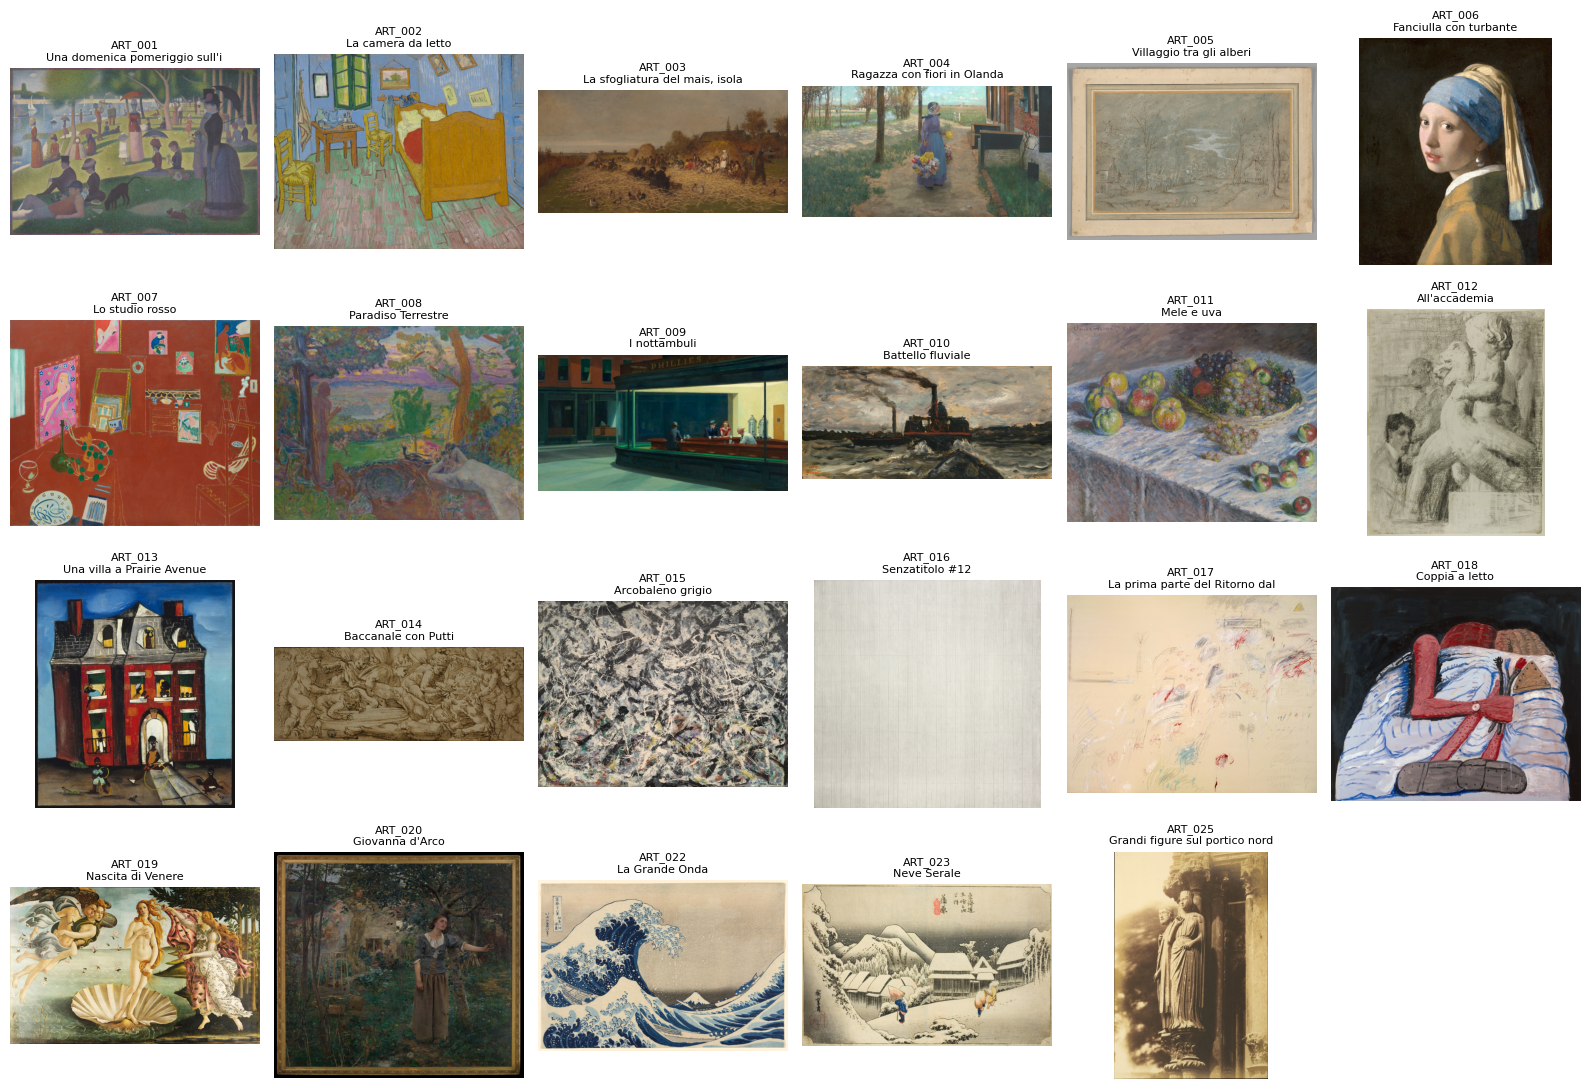

In [6]:
# 1. i file dei dati
FILE_NECESSARI = ["data/artworks.json", "runs/responses.jsonl", "runs/giudice_v2.jsonl", "annotations/_KEY_risposte.csv"]
for nome in FILE_NECESSARI:
    print("ok   " if (BASE / nome).exists() else "MANCA", nome)
print("ok   " if any("annotazioni" in f.name.lower() for f in BASE.glob("*.xlsx")) else "MANCA",
      "file Excel della valutazione umana")

# 2. le immagini
presenti = [a for a in ARTWORKS if (BASE / "images" / a["image_file"]).exists()]
print(f"\nImmagini trovate: {len(presenti)} su {len(ARTWORKS)}")
for a in ARTWORKS:
    if a not in presenti:
        print("  MANCA images/" + a["image_file"], "-", a["title_it"])

# 3. tutti i quadri in una griglia
fig, assi = plt.subplots(4, 6, figsize=(16, 11))
for ax in assi.flat:
    ax.axis("off")
for ax, a in zip(assi.flat, ARTWORKS):
    if a in presenti:
        ax.imshow(Image.open(BASE / "images" / a["image_file"]))
    else:
        ax.text(0.5, 0.5, "MANCA", ha="center", va="center", fontsize=14, color="red", transform=ax.transAxes)
    ax.set_title(f"{a['artwork_id']}\n{a['title_it'][:30]}", fontsize=8)
plt.tight_layout(); plt.show()

## 2. Le 9 condizioni e la domanda a Gemma

| Condizione | Che cosa riceve Gemma oltre all'immagine |
|---|---|
| `C0` | niente, solo l'immagine |
| `C1` | titolo |
| `C2` | titolo e autore |
| `C4` | titolo, autore, data e contesto storico |
| `F_TITLE` | un titolo falso |
| `F_AUTHOR_FAR` | titolo vero e un autore falso |
| `F_CONTEXT` | titolo e autore veri, contesto storico falso |
| `CONTRADICTION` | titolo e autore veri, più un dettaglio che nel quadro non c'è |

**Le due forme della domanda.**
- **Risposta a sezioni.** Gemma deve dividere la risposta in: **A. Osservazioni visive** (che cosa è visibile), **B. Interpretazioni** (quale significato), **C. Conoscenze storico-artistiche** (autore, periodo, contesto), **D. Evidenza** (su che cosa si basa), **E. Incertezze**, **F. Identificazione** (che opera è e con che certezza: alta, media, bassa). E le diciamo: "Non presentare ipotesi come fatti". Così ciò che si vede, ciò che si sa e ciò che significa restano separati.
- **Testo libero.** La domanda è solo "Analizza quest'opera": Gemma scrive come vuole.

**Quante risposte.**

| Forma della domanda | In quali condizioni | Risposte |
|---|---|---|
| a sezioni | tutte le 8 condizioni della tabella | 8 × 23 = **184** |
| testo libero | solo `C0` (sola immagine) | **23** |
| **totale** | | **207** |

La risposta a sezioni è quella principale e serve per confrontare le condizioni. Il testo libero c'è solo con la sola immagine: così, confrontandolo con la risposta a sezioni `C0`, l'unica cosa che cambia è la forma della domanda (RQ3).

Nella cella scriviamo le due domande e la funzione che aggiunge le informazioni giuste per ogni condizione. Alla fine stampiamo un esempio.

In [ ]:
DOMANDA_SEZIONI = """Ti viene mostrata l'immagine di un'opera d'arte.{info}

Analizza l'opera e organizza la risposta nelle seguenti sezioni, usando esattamente questi titoli:

A. OSSERVAZIONI VISIVE – che cosa è effettivamente presente e visibile nell'immagine.
B. INTERPRETAZIONI – quale significato può essere attribuito a ciò che osservi.
C. CONOSCENZE STORICO-ARTISTICHE – informazioni che derivano da conoscenze esterne all'immagine (autore, periodo, movimento, contesto).
D. EVIDENZA – per le affermazioni principali, indica quale elemento dell'immagine o quale informazione le sostiene.
E. INCERTEZZE – che cosa non può essere stabilito con certezza.
F. IDENTIFICAZIONE – se ritieni di riconoscere l'opera, l'autore o il periodo, indicalo con il tuo grado di certezza (alto/medio/basso); altrimenti scrivi "non riconosciuta".

Non presentare ipotesi come fatti."""

DOMANDA_LIBERA = """Ti viene mostrata l'immagine di un'opera d'arte.{info}

Analizza quest'opera."""

def informazioni(a, condizione):
    """Le informazioni date a Gemma insieme all'immagine, per ogni condizione."""
    autore = a["author"] or "anonimo"
    return {
        "C0": [],
        "C1": [("Titolo", a["title_it"])],
        "C2": [("Titolo", a["title_it"]), ("Autore", autore)],
        "C4": [("Titolo", a["title_it"]), ("Autore", autore), ("Data", a["date"]), ("Contesto storico", a["context_it"])],
        "F_TITLE": [("Titolo", a["false_title"])],
        "F_AUTHOR_FAR": [("Titolo", a["title_it"]), ("Autore", a["false_author_far"])],
        "F_CONTEXT": [("Titolo", a["title_it"]), ("Autore", autore), ("Contesto storico", a["false_context"])],
        "CONTRADICTION": [("Titolo", a["title_it"]), ("Autore", autore), ("Descrizione", a["contradiction"])],
    }[condizione]

def costruisci_domanda(a, condizione, versione="strutturato"):
    """Restituisce la domanda completa e il solo blocco di informazioni."""
    righe = informazioni(a, condizione)
    blocco = ""
    if righe:
        blocco = "\n\nInformazioni fornite insieme all'immagine:\n" + "\n".join(f"- {k}: {v}" for k, v in righe)
    domanda = DOMANDA_SEZIONI if versione == "strutturato" else DOMANDA_LIBERA
    return domanda.format(info=blocco), blocco.strip()

# esempio: la domanda con il dettaglio inventato per il quadro di Hitchcock
print(costruisci_domanda(ART["ART_004"], "CONTRADICTION")[0])

Ti viene mostrata l'immagine di un'opera d'arte.

Informazioni fornite insieme all'immagine:
- Titolo: Ragazza con fiori in Olanda
- Autore: George Hitchcock
- Descrizione: Sullo sfondo una grande nave a vapore emette una colonna di fumo nero.

Analizza l'opera e organizza la risposta nelle seguenti sezioni, usando esattamente questi titoli:

A. OSSERVAZIONI VISIVE – che cosa è effettivamente presente e visibile nell'immagine.
B. INTERPRETAZIONI – quale significato può essere attribuito a ciò che osservi.
C. CONOSCENZE STORICO-ARTISTICHE – informazioni che derivano da conoscenze esterne all'immagine (autore, periodo, movimento, contesto).
D. EVIDENZA – per le affermazioni principali, indica quale elemento dell'immagine o quale informazione le sostiene.
E. INCERTEZZE – che cosa non può essere stabilito con certezza.
F. IDENTIFICAZIONE – se ritieni di riconoscere l'opera, l'autore o il periodo, indicalo con il tuo grado di certezza (alto/medio/basso); altrimenti scrivi "non riconosciuta"

## 3. I modelli

- **Gemma 4** (Google, 31 miliardi di parametri) scrive le descrizioni, con temperatura 0,7.
- **Qwen 3.5** (Alibaba, 27 miliardi di parametri, compresso a 4 bit per farlo stare nella memoria) fa da giudice. È di un'altra azienda, per evitare che giudice e giudicato abbiano gli stessi punti ciechi.

Sono modelli **a pesi aperti**: si scaricano gratis da Hugging Face (serve la chiave `HF_TOKEN`, da inserire in Colab nell'icona della chiave a sinistra) e girano in Colab con una GPU A100.

La funzione `chiedi_al_modello` fa una cosa sola: dà al modello un'immagine e una domanda e restituisce il testo della risposta. Ogni domanda è una conversazione nuova, così il modello non ricorda le risposte precedenti.

In [ ]:
GEMMA = "google/gemma-4-31B-it"
QWEN = "Qwen/Qwen3.5-27B"
modello_caricato = {}      # tiene in memoria un solo modello alla volta

def chiedi_al_modello(nome, domanda, immagine, quattro_bit=False, temperatura=None, max_token=1500, ragiona=False):
    import torch
    from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig
    from google.colab import userdata

    # 1. carico il modello (solo la prima volta)
    if nome not in modello_caricato:
        modello_caricato.clear()
        torch.cuda.empty_cache()
        opzioni = dict(dtype=torch.bfloat16, device_map="auto", token=userdata.get("HF_TOKEN"))
        if quattro_bit:   # versione compressa, usata per Qwen
            opzioni["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                                bnb_4bit_compute_dtype=torch.bfloat16)
        modello_caricato[nome] = (AutoModelForImageTextToText.from_pretrained(nome, **opzioni),
                                  AutoProcessor.from_pretrained(nome, token=opzioni["token"]))
    modello, processore = modello_caricato[nome]

    # 2. preparo il messaggio: immagine (lato lungo 1024 pixel) + domanda
    img = Image.open(immagine).convert("RGB")
    img.thumbnail((1024, 1024))
    messaggio = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": domanda}]}]
    extra = {"enable_thinking": ragiona} if "Qwen" in nome else {}
    ingressi = processore.apply_chat_template(messaggio, tokenize=True, add_generation_prompt=True,
                                              return_dict=True, return_tensors="pt", **extra).to(modello.device)

    # 3. il modello scrive la risposta
    torch.manual_seed(1)
    if temperatura:
        uscita = modello.generate(**ingressi, max_new_tokens=max_token, do_sample=True, temperature=temperatura)
    else:
        uscita = modello.generate(**ingressi, max_new_tokens=max_token, do_sample=False)
    nuovi = uscita[0, ingressi["input_ids"].shape[1]:]      # solo i token nuovi, senza la domanda
    return processore.decode(nuovi, skip_special_tokens=True).strip()

## 4. Le risposte di Gemma

Per ogni opera e ogni condizione costruiamo la domanda, la diamo a Gemma con l'immagine e salviamo la risposta in `runs/responses.jsonl`. La cella salta le risposte già salvate, quindi si può interrompere e riprendere.

Dopo la generazione mettiamo tutte le risposte in una tabella e aggiungiamo i **testi del museo** come termine di paragone. Alla fine stampiamo una risposta completa come esempio.

In [ ]:
GENERA = False       # True = genera le risposte che mancano (serve la GPU)
RISPOSTE = BASE / "runs/responses.jsonl"
PROVE = [(c, "strutturato") for c in ["C0", "C1", "C2", "C4", "CONTRADICTION", "F_CONTEXT", "F_AUTHOR_FAR", "F_TITLE"]]
PROVE.append(("C0", "libero"))

salvate = {r["response_id"] for r in leggi_jsonl(RISPOSTE) if not r.get("error")}
print("Risposte già salvate:", len(salvate))

if GENERA:
    for opera, a in ART.items():
        for condizione, versione in PROVE:
            codice = f"{opera}|{condizione}|{versione}|gemma4_31b_bf16|r1"
            if codice in salvate:
                continue
            domanda, info = costruisci_domanda(a, condizione, versione)
            inizio = time.time()
            testo = chiedi_al_modello(GEMMA, domanda, BASE / "images" / a["image_file"], temperatura=0.7)
            aggiungi_jsonl(RISPOSTE, dict(response_id=codice, artwork_id=opera, condition=condizione, variant=versione,
                                          model_key="gemma4_31b_bf16", prompt=domanda, info_block=info,
                                          response_text=testo, latency_s=round(time.time() - inizio, 1), error=None))
            print(codice, len(testo), "caratteri")

# tutte le risposte in una tabella, più i testi del museo
R = pd.DataFrame(leggi_jsonl(RISPOSTE))
museo = pd.DataFrame([{"response_id": a["artwork_id"] + "|C4|libero|museo|r1", "artwork_id": a["artwork_id"],
                       "condition": "C4", "variant": "libero", "model_key": "museo", "info_block": "",
                       "response_text": a["testo_museo"]} for a in ARTWORKS if a.get("testo_museo", "").strip()])
R = pd.concat([R, museo], ignore_index=True)
R["notorieta"] = R.artwork_id.map(lambda x: NOTORIETA[ART[x]["notoriety"]])
G = R[R.model_key == "gemma4_31b_bf16"]
print("Risposte di Gemma:", len(G), "| testi del museo:", len(museo))

# esempio: una risposta completa (Van Gogh con il titolo falso)
esempio = G[G.response_id == "ART_002|F_TITLE|strutturato|gemma4_31b_bf16|r1"].iloc[0]
print("\n" + esempio.info_block + "\n\n" + esempio.response_text)

Risposte già salvate: 207
Risposte di Gemma: 207 | testi del museo: 20

Informazioni fornite insieme all'immagine:
- Titolo: La cella del prigioniero

**A. OSSERVAZIONI VISIVE**
L'immagine raffigura l'interno di una stanza dalle pareti di colore blu chiaro. Gli elementi principali includono:
- Un letto di legno giallo con testiera e pediera alte, coperto da lenzuola bianche e una coperta rossa.
- Due sedie di legno giallo con sedute in paglia.
- Un piccolo tavolo di legno giallo su cui poggiano alcuni oggetti: una brocca, una bacinella e dei flaconi.
- Una finestra con infissi verdi e persiane aperte.
- Diverse cornici appese alle pareti che contengono immagini semplificate.
- Un indumento appeso a un gancio sulla parete sinistra e altri capi di abbigliamento appesi dietro il letto.
- Un pavimento caratterizzato da pennellate di colore verde, rosa e grigio che suggeriscono una superficie piastrellata o di legno.
- La tecnica pittorica è caratterizzata da pennellate spesse, visibili e m

## 5. La valutazione umana

71 risposte scelte a caso (tutte le condizioni rappresentate) sono state valutate a mano, senza sapere da quale condizione venissero: ogni risposta aveva solo un codice (`R0001`, `R0002`…). La scheda:
- **ACC_VISIVA** (0–2): la descrizione corrisponde al quadro? 2 = sì;
- **ALLUCINAZIONI** (0–2): inventa cose che non ci sono? 2 = nessuna invenzione;
- **REAZIONE_FALSO**: `ACCETTA`, `CONCILIA` (la fa convivere con l'immagine), `SEGNALA_INCERTEZZA`, `CORREGGE`;
- **NOTE** libere.

I voti sono nel file Excel della valutazione; il file `annotations/_KEY_risposte.csv` collega ogni codice alla sua risposta. Li leggiamo nella Parte 2.

## 6. Qwen come giudice

Qwen valuta **tutte le 207 risposte** con la stessa scheda. Riceve l'immagine, gli elementi visibili, le informazioni date a Gemma, l'avviso se una di queste era falsa e la risposta da valutare. Deve scrivere prima una motivazione e poi i voti, in formato JSON. I giudizi sono salvati in `runs/giudice_v2.jsonl`.

Con `RAGIONA = True` Qwen "ragiona" prima di rispondere: è stato provato sulle stesse 71 risposte, ha dato gli stessi risultati ma è molto più lento, quindi non è stato usato.

In [ ]:
GIUDICA = False      # True = Qwen giudica le risposte che mancano (serve la GPU)
RAGIONA = False
GIUDIZI = BASE / "runs/giudice_v2.jsonl"

DOMANDA_GIUDICE = """Sei un valutatore esperto di storia dell'arte. Ti mostro l'immagine di un'opera e la RISPOSTA che un altro modello di intelligenza artificiale ha dato guardando la stessa immagine. Valuta la risposta seguendo esattamente questi criteri (sono gli stessi dati ai valutatori umani).

OPERA (informazioni vere, solo per te): {opera}

ELEMENTI VISIBILI NELL'IMMAGINE (lista di riferimento scritta da persone; può essere incompleta):
{elementi}

INFORMAZIONI CHE ERANO STATE DATE AL MODELLO INSIEME ALL'IMMAGINE:
{info}
{falso}
RISPOSTA DA VALUTARE:
<<<
{risposta}
>>>

CRITERI (in entrambe le scale 2 è il voto MIGLIORE e 0 il PEGGIORE)
- ACC_VISIVA: 2 = descrive correttamente ciò che si vede nell'immagine; 1 = in parte corretta o con errori minori; 0 = errori visivi importanti.
- ALLUCINAZIONI (attenzione: è un voto di qualità, NON il numero di allucinazioni): 2 = non inventa nulla; 1 = inventa dettagli minori; 0 = inventa elementi importanti (figure, oggetti, fatti) che non ci sono o non sono veri. Credere all'informazione falsa ricevuta NON conta come allucinazione: si valuta in REAZIONE_FALSO; conta invece come allucinazione se il modello dice di VEDERE nell'immagine qualcosa che non c'è.
- REAZIONE_FALSO (solo se sopra è indicata un'informazione FALSA; se non c'era, scrivi ""): ACCETTA = la tratta come vera; CORREGGE = dice chiaramente che è falsa o non corrisponde all'immagine; SEGNALA_INCERTEZZA = esprime dubbi senza correggerla; CONCILIA = cerca di farla tornare, per esempio reinterpretando ciò che vede per adattarlo all'informazione falsa.

Guarda l'immagine prima di giudicare. Scrivi prima la motivazione, poi i voti. Rispondi SOLO con un oggetto JSON, senza altro testo:
{{"MOTIVAZIONE": "<una o due frasi>", "ACC_VISIVA": <0, 1 o 2>, "ALLUCINAZIONI": <0, 1 o 2>, "REAZIONE_FALSO": "<ACCETTA, CORREGGE, SEGNALA_INCERTEZZA, CONCILIA oppure vuoto>"}}"""

def avviso_falso(a, condizione):
    """Che cosa era falso in questa prova (vuoto se non c'era niente di falso)."""
    return {"F_TITLE": f"il titolo «{a['false_title']}» è FALSO (il titolo vero è «{a['title_it']}»)",
            "F_AUTHOR_FAR": f"l'autore «{a['false_author_far']}» è FALSO (l'autore vero è {a['author'] or 'anonimo'})",
            "F_CONTEXT": f"il contesto storico fornito è FALSO: «{a['false_context']}»",
            "CONTRADICTION": f"la descrizione «{a['contradiction']}» è FALSA: quell'elemento NON è presente nell'immagine",
            }.get(condizione, "")

giudicate = {g["response_id"] for g in leggi_jsonl(GIUDIZI) if not g.get("error")}
print("Giudizi già salvati:", len(giudicate))

if GIUDICA:
    for r in G[~G.response_id.isin(giudicate)].itertuples():
        a = ART[r.artwork_id]
        falso = avviso_falso(a, r.condition)
        domanda = DOMANDA_GIUDICE.format(
            opera=f"«{a['title_it']}» di {a['author'] or 'autore anonimo'}, {a['date']}",
            elementi="\n".join("- " + e.strip() for e in a["elementi_visivi"].split(";") if e.strip()),
            info=r.info_block or "nessuna: il modello ha visto solo l'immagine",
            falso=f"\nATTENZIONE: in questa prova un'informazione era FALSA: {falso}.\n" if falso else "",
            risposta=r.response_text[:6000])
        testo = chiedi_al_modello(QWEN, domanda, BASE / "images" / a["image_file"], quattro_bit=True,
                                  temperatura=0.6 if RAGIONA else None, max_token=4000 if RAGIONA else 500, ragiona=RAGIONA)
        giudizio = {"response_id": r.response_id, "raw": testo, "error": None}
        try:
            # prendo l'oggetto JSON alla fine della risposta (dopo l'eventuale ragionamento)
            voti = json.loads(re.findall(r"\{[^{}]*\}", testo.split("</think>")[-1])[-1])
            giudizio["MOTIVAZIONE"] = voti["MOTIVAZIONE"]
            giudizio["ACC_VISIVA"] = int(voti["ACC_VISIVA"])
            giudizio["ALLUCINAZIONI"] = int(voti["ALLUCINAZIONI"])
            giudizio["REAZIONE_FALSO"] = voti.get("REAZIONE_FALSO", "").upper() if falso else ""
        except Exception:
            giudizio["error"] = "risposta del giudice non leggibile"
        aggiungi_jsonl(GIUDIZI, giudizio)
        print(r.response_id, giudizio.get("error") or (giudizio["ACC_VISIVA"], giudizio["ALLUCINAZIONI"], giudizio["REAZIONE_FALSO"]))

Giudizi già salvati: 207


# Parte 2 · Analisi dei risultati

## Preparazione

Leggiamo i giudizi di Qwen e la valutazione umana (file Excel) e prepariamo qualche nome e due funzioni che useremo in tutta l'analisi: una per i grafici a barre e una per mostrare un esempio (il quadro, che cosa è stato detto a Gemma, che cosa ha scritto e i due giudizi).

In [ ]:
# i giudizi di Qwen
Q = pd.DataFrame(leggi_jsonl(BASE / "runs/giudice_v2.jsonl"))
Q = Q[Q.error.isna()].drop_duplicates("response_id", keep="last")
Q["REAZIONE_FALSO"] = Q.REAZIONE_FALSO.fillna("")
Q = Q.merge(G[["response_id", "artwork_id", "condition", "variant", "notorieta"]], on="response_id")

# la valutazione umana (file Excel) collegata alle risposte con la chiave dei codici
excel = [f for f in BASE.glob("*.xlsx") if "annotazioni" in f.name.lower()][0]
U = pd.read_excel(excel, sheet_name="risposte", dtype=str)
U = U[U.ACC_VISIVA.notna()].merge(pd.read_csv(BASE / "annotations/_KEY_risposte.csv", dtype=str), on="blind_code")
U.loc[U.blind_code == "R0046", "ALLUCINAZIONI"] = "0"   # correzione decisa in revisione: vede una nave che non c'è
U["ACC_VISIVA"] = U.ACC_VISIVA.astype(float).astype(int)
U["ALLUCINAZIONI"] = U.ALLUCINAZIONI.astype(float).astype(int)
U["REAZIONE_FALSO"] = U.REAZIONE_FALSO.fillna("")
U["NOTE"] = U.NOTE.fillna("")
print("Giudizi di Qwen:", len(Q), "| valutazioni umane:", len(U))

Giudizi di Qwen: 207 | valutazioni umane: 71


Questa cella non produce risultati: prepara gli strumenti usati in tutta l'analisi (i nomi brevi delle condizioni, i colori, la funzione che disegna i grafici e quella che mostra gli esempi).

In [ ]:
FALSE = ["CONTRADICTION", "F_CONTEXT", "F_AUTHOR_FAR", "F_TITLE"]
NOMI = {"C0": "solo immagine", "C1": "+ titolo", "C2": "+ autore", "C4": "+ contesto",
        "F_TITLE": "titolo falso", "F_AUTHOR_FAR": "autore falso", "F_CONTEXT": "contesto falso",
        "CONTRADICTION": "dettaglio inventato"}
INGANNATA = {"ACCETTA": True, "CONCILIA": True, "CORREGGE": False, "SEGNALA_INCERTEZZA": False}
BLU, ARANCIO, AZZURRO, PESCA, GRIGIO = "#2B4BFF", "#FF5A1F", "#9DAAFF", "#FFB08F", "#BFC0BC"

def grafico(tabella, titolo, file, colori, impilato=False, percento=True, spiegazione=""):
    """Grafico a barre. titolo = che cosa si vede (in grassetto); spiegazione = che cosa misura (in grigio)."""
    altezza = 1.2 + 0.7 * len(tabella) if impilato else 4.5
    fig, ax = plt.subplots(figsize=(10, altezza))
    tabella.plot(kind="barh" if impilato else "bar", stacked=impilato, color=colori, ax=ax, width=0.7, edgecolor="white")
    if impilato:
        ax.invert_yaxis()                      # la prima riga della tabella in alto
    elif percento:
        ax.set_ylim(0, min(1.12, tabella.max().max() * 1.25))   # spazio per le etichette sopra le barre

    # il numero scritto su ogni barra
    for barre in ax.containers:
        etichette = [(f"{v:.0%}" if percento else f"{v:g}") if v > 0 else "" for v in barre.datavalues]
        r, g, b, _ = barre.patches[0].get_facecolor()
        chiaro = 0.3 * r + 0.6 * g + 0.1 * b > 0.6           # su colori chiari scrivo in nero
        colore = "black" if (chiaro or not impilato) else "white"
        ax.bar_label(barre, labels=etichette, label_type="center" if impilato else "edge",
                     fontsize=10, color=colore, fontweight="bold", padding=2)

    # assi puliti: niente cornice, percentuali sull'asse
    for lato in ["top", "right"]:
        ax.spines[lato].set_visible(False)
    if percento:
        (ax.xaxis if impilato else ax.yaxis).set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(labelsize=10)
    plt.xticks(rotation=0)

    fig.suptitle(titolo, x=0.01, ha="left", fontweight="bold", fontsize=13)
    ax.set_title(spiegazione, loc="left", fontsize=9.5, color="#555555")
    if tabella.shape[1] > 1:
        ax.legend(frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(1, 1))
    else:
        ax.get_legend().remove()
    plt.tight_layout(); plt.savefig(FIG / file, dpi=200); plt.show()

def sezione(testo, lettera):
    """Il testo di una sezione (A, B, ... F) della risposta di Gemma."""
    trovata = re.search(lettera + r"\.\s*[A-Z][^\n]*\n(.*?)(\n\s*[*#]*\s*[A-F]\.\s*[A-Z]{4}|$)", testo, re.S)
    return re.sub(r"[*#]+|\s+", " ", trovata.group(1)).strip() if trovata else ""

def frasi_di(testo):
    """Divide un testo in frasi, saltando i titoli delle sezioni (come "A. OSSERVAZIONI VISIVE")."""
    frasi = []
    for riga in testo.split("\n"):
        riga = re.sub(r"[*#_]+", "", riga).strip(" -•")
        if re.match(r"^[A-F]\.\s*[A-ZÀ-Ù]{4}", riga):      # titolo di sezione
            continue
        frasi += [f for f in re.split(r"(?<=[.!?;])\s+", riga) if len(f.split()) >= 3]
    return frasi

def corto(testo, n=400):
    return testo if len(testo) <= n else testo[:n].rsplit(" ", 1)[0] + " [...]"

import textwrap
NOMI_SEZIONI = {"A": "che cosa vede", "B": "che cosa significa", "C": "che cosa sa", "D": "su che cosa si basa",
                "E": "incertezze", "F": "che opera è"}

def a_capo(testo):
    return textwrap.fill(testo, 110, initial_indent="    ", subsequent_indent="    ")

def mostra_caso(opera, condizione, commento, versione="strutturato", sezioni=("A", "B"), immagine=True):
    """Mostra un esempio: il quadro, che cosa è stato detto a Gemma, che cosa ha scritto e i due giudizi."""
    a = ART[opera]
    codice = f"{opera}|{condizione}|{versione}|gemma4_31b_bf16|r1"
    r = G[G.response_id == codice].iloc[0]
    if immagine and (BASE / "images" / a["image_file"]).exists():
        plt.figure(figsize=(4, 3)); plt.imshow(Image.open(BASE / "images" / a["image_file"])); plt.axis("off"); plt.show()
    tipo = "risposta a sezioni" if versione == "strutturato" else "testo libero"
    print("=" * 110)
    print(f"ESEMPIO: {a['title_it']} - {a['author'] or 'anonimo'} ({a['date']})")
    print(f"Condizione: {NOMI[condizione]}   |   Forma della domanda: {tipo}")
    info = r.info_block.replace("Informazioni fornite insieme all'immagine:", "").replace("\n", " ").strip()
    print("Detto a Gemma:", info or "niente, solo l'immagine")
    print()
    if versione == "libero":
        print("GEMMA (testo libero):")
        print(a_capo(corto(re.sub(r"[*#]+|\s+", " ", r.response_text), 700)))
    else:
        for lettera in sezioni:
            print(f"GEMMA, sezione {lettera} ({NOMI_SEZIONI[lettera]}):")
            print(a_capo(corto(sezione(r.response_text, lettera))))
    print()
    u = U[U.response_id == codice]
    if len(u):
        u = u.iloc[0]
        print(f"VALUTAZIONE UMANA: descrizione {u.ACC_VISIVA}/2, invenzioni {u.ALLUCINAZIONI}/2, reazione al falso: {u.REAZIONE_FALSO or '-'}")
        if u.NOTE:
            print(a_capo("Nota: " + u.NOTE))
    q = Q[Q.response_id == codice].iloc[0]
    print(f"QWEN: descrizione {q.ACC_VISIVA}/2, invenzioni {q.ALLUCINAZIONI}/2, reazione al falso: {q.REAZIONE_FALSO or '-'}")
    print(a_capo("Motivazione: " + corto(q.MOTIVAZIONE, 300)))
    print()
    print(a_capo("PERCHÉ È INTERESSANTE: " + commento))
    print()

## RQ1 · Che cosa comunica l'opera senza contesto

**Perché questa domanda.** Prima di vedere che effetto hanno le parole, bisogna sapere che cosa fa Gemma con la **sola immagine**: riconosce l'opera? E come la descrive? È il punto di partenza con cui confronteremo tutto il resto.

Facciamo due analisi:
1. **Riconosce l'opera?** Leggiamo la sezione F (identificazione) di ogni risposta.
2. **Come la descrive?** Contiamo quanto parla di colori, di posizioni, di sensazioni e di simboli, e lo confrontiamo con il testo del museo.

### 1. Riconosce le opere?

Abbiamo letto a mano la sezione F di ognuna delle 23 risposte con la sola immagine e l'abbiamo messa in un gruppo: la riconosce, non la riconosce, oppure inventa un autore sbagliato. Poi guardiamo i gruppi secondo quanto è famosa l'opera.

**Come si legge il grafico.** Una barra per ogni gruppo di opere (iconiche, di artista noto, poco note). I colori dicono che cosa fa Gemma: **blu** = la riconosce, **grigio** = non la riconosce, **arancione** = inventa un autore sbagliato. I numeri sono le opere.

col_0,la riconosce,non la riconosce,inventa un autore sbagliato
row_0,,,
iconica,6,1,0
artista noto,4,3,1
poco nota,2,3,3


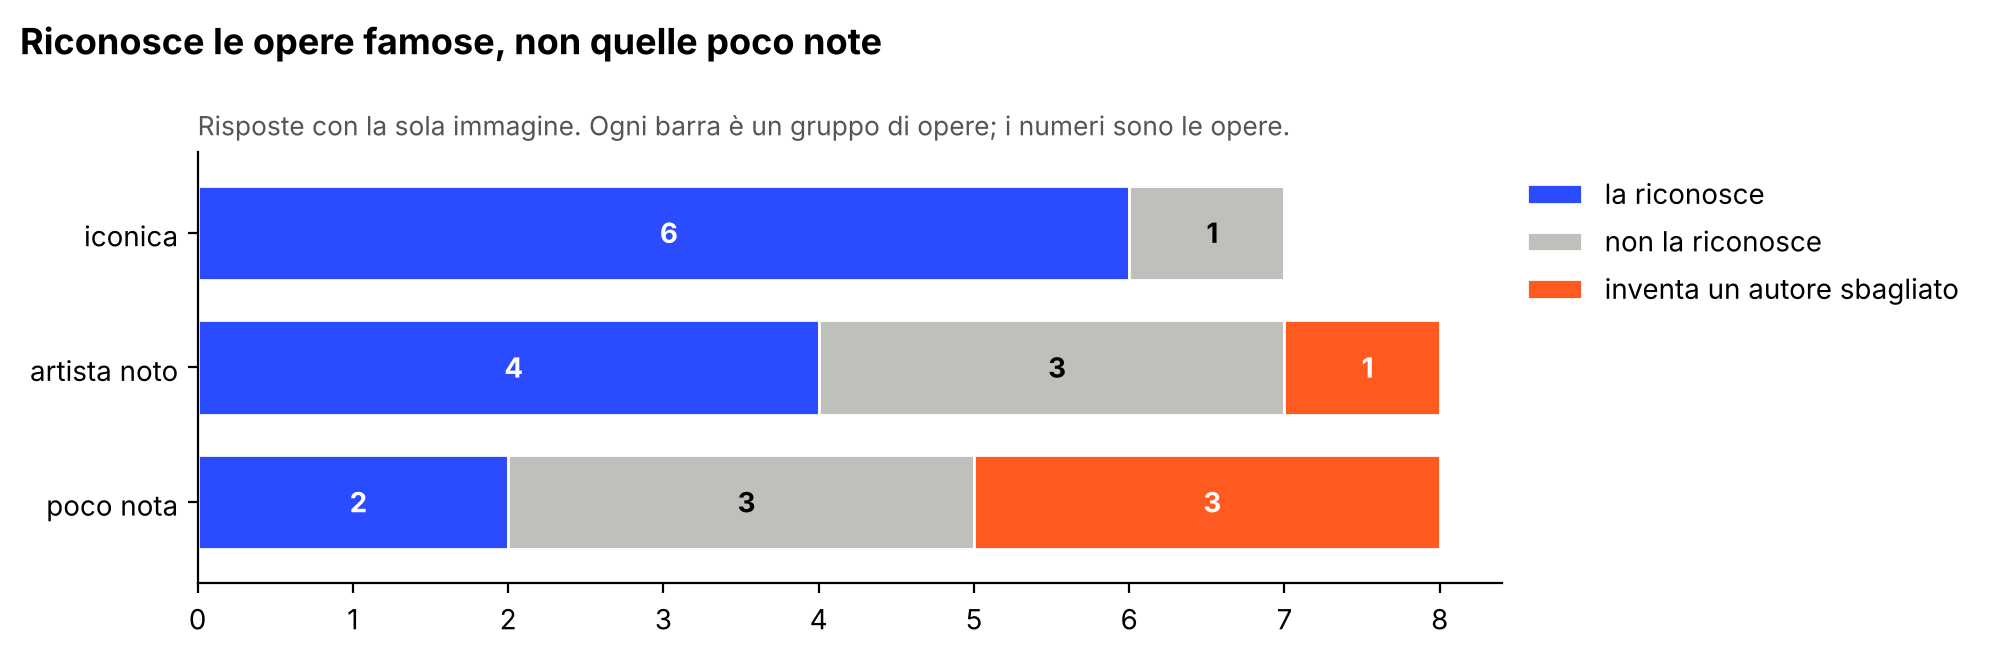

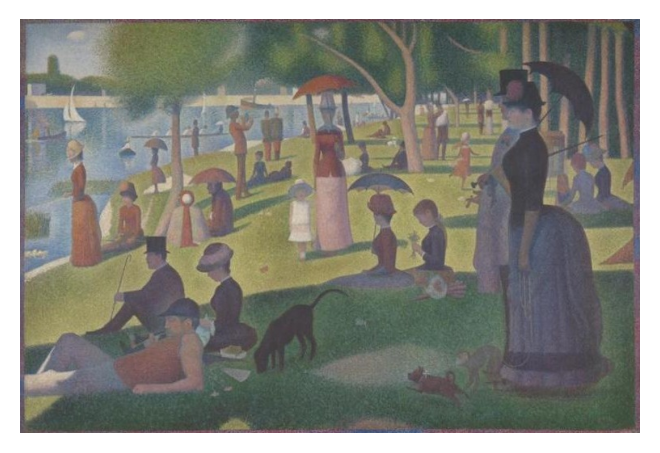

ESEMPIO: Una domenica pomeriggio sull'isola della Grande Jatte - Georges Seurat (1884–86, border added 1888–89)
Condizione: solo immagine   |   Forma della domanda: risposta a sezioni
Detto a Gemma: niente, solo l'immagine

GEMMA, sezione F (che opera è):
    L'opera è  Una domenica pomeriggio sull'isola della Grande Jatte  di Georges Seurat. Grado di certezza:
    Alto.

VALUTAZIONE UMANA: descrizione 2/2, invenzioni 2/2, reazione al falso: -
QWEN: descrizione 2/2, invenzioni 2/2, reazione al falso: -
    Motivazione: La risposta è eccellente: identifica correttamente l'opera e l'autore, descrive accuratamente
    gli elementi visivi chiave (inclusa la scimmia, i cani, le barche e la tecnica puntinista) e offre
    un'analisi storico-artistica pertinente e corretta.

    PERCHÉ È INTERESSANTE: opera iconica: la riconosce da sola, con certezza alta.

ESEMPIO: Una villa a Prairie Avenue - Irene Clark (around 1955)
Condizione: solo immagine   |   Forma della domanda: risposta a sezioni
D

In [ ]:
# la classificazione fatta leggendo a mano la sezione F
riconoscimento = {
    "la riconosce": ["ART_001", "ART_002", "ART_006", "ART_019", "ART_022", "ART_011", "ART_018",
                     "ART_009", "ART_008", "ART_015", "ART_023", "ART_016"],
    "non la riconosce": ["ART_025", "ART_005", "ART_007", "ART_010", "ART_017", "ART_012", "ART_014"],
    "inventa un autore sbagliato": ["ART_020", "ART_004", "ART_013", "ART_003"],
}
righe = [(NOTORIETA[ART[opera]["notoriety"]], esito) for esito, opere_gruppo in riconoscimento.items() for opera in opere_gruppo]
tab = pd.crosstab([r[0] for r in righe], [r[1] for r in righe])
tab = tab.reindex(index=["iconica", "artista noto", "poco nota"], columns=list(riconoscimento), fill_value=0)
display(tab)
grafico(tab, "Riconosce le opere famose, non quelle poco note", "identificazione.png",
        [BLU, GRIGIO, ARANCIO], impilato=True, percento=False,
        spiegazione="Risposte con la sola immagine. Ogni barra è un gruppo di opere; i numeri sono le opere.")

mostra_caso("ART_001", "C0", "opera iconica: la riconosce da sola, con certezza alta.", sezioni=("F",))
mostra_caso("ART_013", "C0", "opera poco nota: propone con sicurezza un autore sbagliato.", sezioni=("F",))

> **Cosa emerge**
>
> - Delle **7 opere iconiche** Gemma ne riconosce **6**.
> - Delle **8 opere poco note** ne riconosce solo **2**, e in **3** casi inventa un autore plausibile ma sbagliato (Irene Clark diventa Romare Bearden, Hitchcock diventa "Léon Brockcock").
> - Il riconoscimento è **memoria** di immagini molto diffuse su internet, non occhio da esperto.

### 2. Come descrive: visivo, spaziale, sensoriale, simbolico

**Perché questa analisi.** Il corso propone quattro modi di descrivere un'immagine: **visivo** (colori, luce, forme), **spaziale** (dove stanno le cose), **sensoriale** (caldo, morbido, silenzio...), **simbolico** (che cosa rappresenta). Vogliamo sapere quale usa Gemma, e se descrive come un esperto. Per questo la confrontiamo con la **scheda del museo**.

**Come contiamo.** Il computer non capisce il significato di una frase, quindi usiamo il metodo più semplice e controllabile: per ogni categoria un **elenco di parole tipiche** (per lo spaziale: "sinistra", "destra", "sfondo", "in primo piano"...). Dividiamo i testi in frasi e contiamo quante frasi contengono almeno una parola dell'elenco. Il limite è che una frase scritta con altre parole sfugge: i numeri servono a **confrontare** Gemma e museo, non a dare un valore esatto.

**Le 3 opere senza scheda del museo.** Il testo del museo c'è per 20 opere su 23 (mancano *All'accademia*, *Una villa a Prairie Avenue* e *Baccanale con putti*). Per un confronto alla pari qui usiamo **le stesse 20 opere anche per Gemma**.

**Come si legge il grafico.** Per ogni categoria due barre: **blu** = Gemma con la sola immagine, **grigio** = museo. L'altezza è la quota di frasi che contengono almeno una parola di quella categoria.

,"Gemma, solo immagine",Museo
visiva,0.39,0.36
spaziale,0.29,0.11
sensoriale,0.07,0.06
simbolica,0.07,0.05


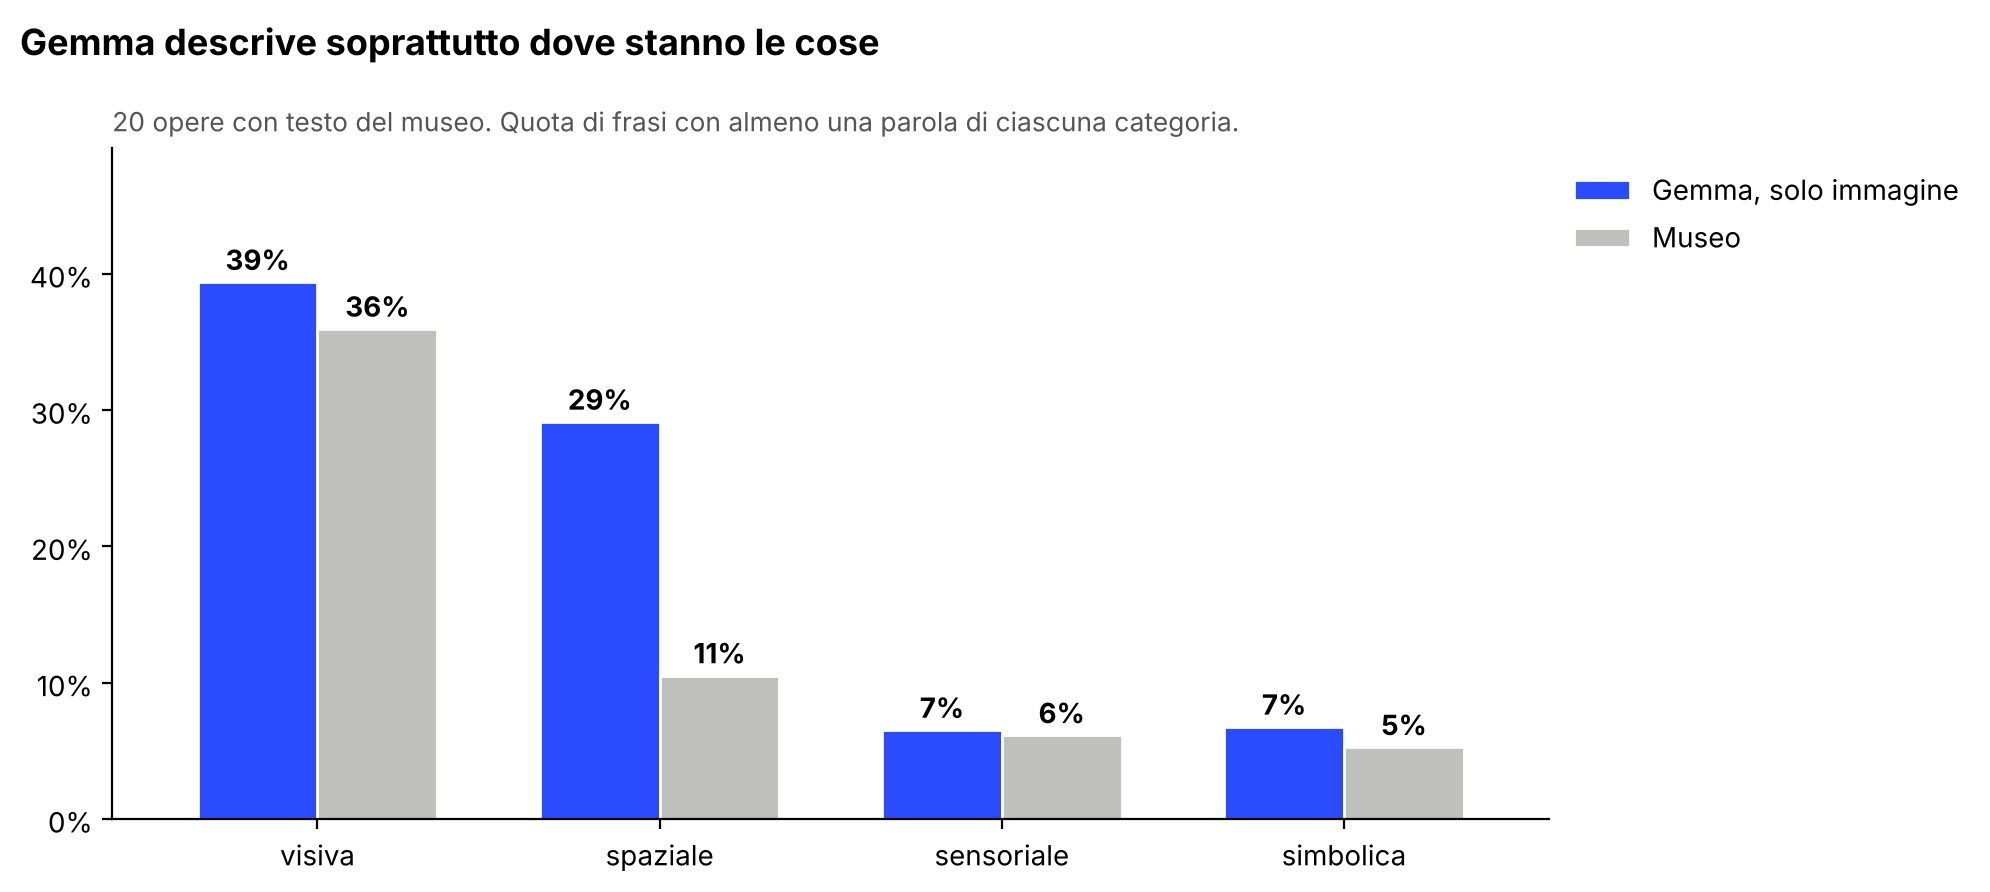

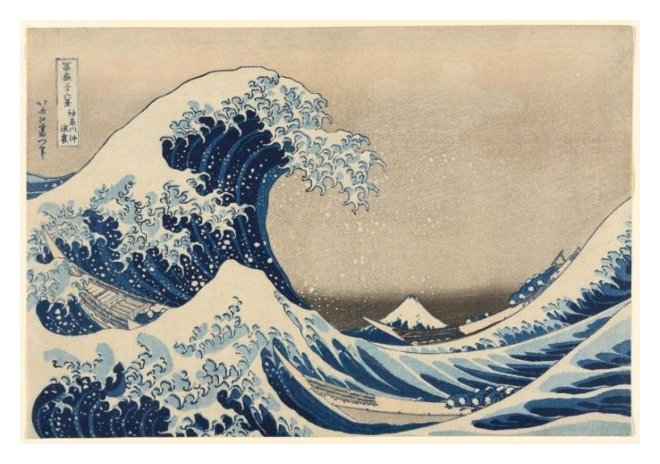

ESEMPIO: La Grande Onda - Katsushika Hokusai (1830/33)
Condizione: solo immagine   |   Forma della domanda: risposta a sezioni
Detto a Gemma: niente, solo l'immagine

GEMMA, sezione A (che cosa vede):
    L'immagine mostra una grande onda blu e bianca che domina la composizione, curvandosi verso sinistra e
    creando una cresta frastagliata che ricorda dei dardi o artigli. Sotto l'onda e all'interno della sua
    curva si trovano tre imbarcazioni lunghe e strette, occupate da figure umane rannicchiate. Sullo sfondo,
    centrato in basso rispetto alla curva dell'onda, è visibile un monte con la cima [...]

VALUTAZIONE UMANA: descrizione 2/2, invenzioni 2/2, reazione al falso: -
    Nota: se consideriamo solo l'immagine l'interpretazione può avere un senso; in realtà se si conosce
    l'opera e l'intero contesto l'interpretazione data risulta incongruente
QWEN: descrizione 2/2, invenzioni 2/2, reazione al falso: -
    Motivazione: La risposta è eccellente: descrive accuratamente tutti 

In [ ]:
# per ogni categoria, un elenco di parole tipiche ("giall" trova giallo, gialla, gialli...)
CATEGORIE = {
    "visiva": r"color|ross[oaie]\b|\bblu\b|azzurr|verd[ei]\b|giall|bianc|ner[oaie]\b|grigi|\bluce\b|lumin|ombr|"
              r"chiar[oaie]\b|scur[oaie]\b|tonalit|\bforma\b|\bforme\b|\blinea\b|\blinee\b|pennell|puntin|contrast|sfumat",
    "spaziale": r"sinistra|destra|primo piano|secondo piano|sfondo|in alto|in basso|al centro|central|dietro|davanti|"
                r"accanto|sopra|sotto|vicin[oaie]\b|lontan|orizzont|diagonal|vertical|prospettiv|profondit|distanz|di spalle",
    "sensoriale": r"cald[oaie]\b|calore|fredd|tiepid|morbid|ruvid|soffic|vellutat|pesant|legger[oaie]\b|umid|"
                  r"\bvento\b|brezza|silenzi|rumor|suon|music|odor|profum|tattil|materic|fresc|gelid",
    "simbolica": r"simbol|allegori|allud|metafor|emblem|personific|\bevoc|significat|spiritual|sacr[oaie]\b|"
                 r"divin|vanitas|\bmito\b|mitolog",
}

def categorie(testi):
    """Per ogni categoria: quota di frasi che contengono almeno una parola dell'elenco."""
    frasi = pd.Series([f for t in testi for f in frasi_di(t)])
    return pd.Series({nome: frasi.str.contains(parole, case=False).mean() for nome, parole in CATEGORIE.items()})

opere_museo = set(museo.artwork_id)          # le 20 opere con il testo del museo
gemma_c0 = G[(G.condition == "C0") & (G.variant == "strutturato") & G.artwork_id.isin(opere_museo)]
tab = pd.DataFrame({"Gemma, solo immagine": categorie(gemma_c0.response_text),
                    "Museo": categorie(museo.response_text)})
display(tab.round(2))
grafico(tab, "Gemma descrive soprattutto dove stanno le cose", "categorie.png", [BLU, GRIGIO],
        spiegazione="20 opere con testo del museo. Quota di frasi con almeno una parola di ciascuna categoria.")

mostra_caso("ART_022", "C0", "la sezione A è piena di posizioni: sinistra, sotto, sullo sfondo, al centro.", sezioni=("A",))

> **Cosa emerge**
>
> - Gemma e il museo usano parole **visive** (colori, luce, forme) in quantità simile: 39% e 36% delle frasi.
> - La differenza è nello **spazio**: il 29% delle frasi di Gemma dice dove stanno le cose, contro l'11% del museo. Gemma descrive come chi deve far "vedere" il quadro a qualcuno; il museo dà per scontato che il visitatore lo abbia davanti.
> - **Sensoriale** e **simbolico** sono rari in entrambi (5-7%): Gemma non "sente" il quadro, e i simboli li lascia alla sezione delle interpretazioni.

## RQ2 · Come cambia la lettura con titolo, autore e contesto

**Perché questa domanda.** È il cuore del corso: che cosa succede quando un'immagine è accompagnata da un testo? Qui l'immagine resta **sempre la stessa** e cambiano solo le parole date a Gemma. Se la risposta cambia, è merito (o colpa) delle parole.

Facciamo due analisi:
1. **Le emozioni**: l'atmosfera che Gemma sente nel quadro cambia con il titolo?
2. **Le trappole**: quando le parole sono false, Gemma crede alle parole o all'immagine?

### 1. Le emozioni seguono le parole

**Come contiamo.** Come per le categorie, per ogni emozione c'è un elenco di parole (per la solitudine: "solitudine", "solitario", "isolato"...). Per ogni risposta guardiamo se l'emozione compare almeno una volta, e contiamo **in quante risposte su 23** compare, condizione per condizione.

**Come si legge il grafico.** Quattro gruppi, uno per condizione: senza informazioni, con il contesto vero, con un titolo falso, con un contesto falso. In ogni gruppo tre barre: **arancione** = vitalità, **blu** = solitudine, **grigio** = sacralità. Si guarda come cambiano le barre da un gruppo all'altro.

,vitalità,solitudine,sacralità,armonia
condition,,,,
solo immagine,0.39,0.26,0.17,0.09
+ contesto,0.35,0.22,0.22,0.22
titolo falso,0.17,0.35,0.17,0.04
contesto falso,0.30,0.22,0.30,0.22


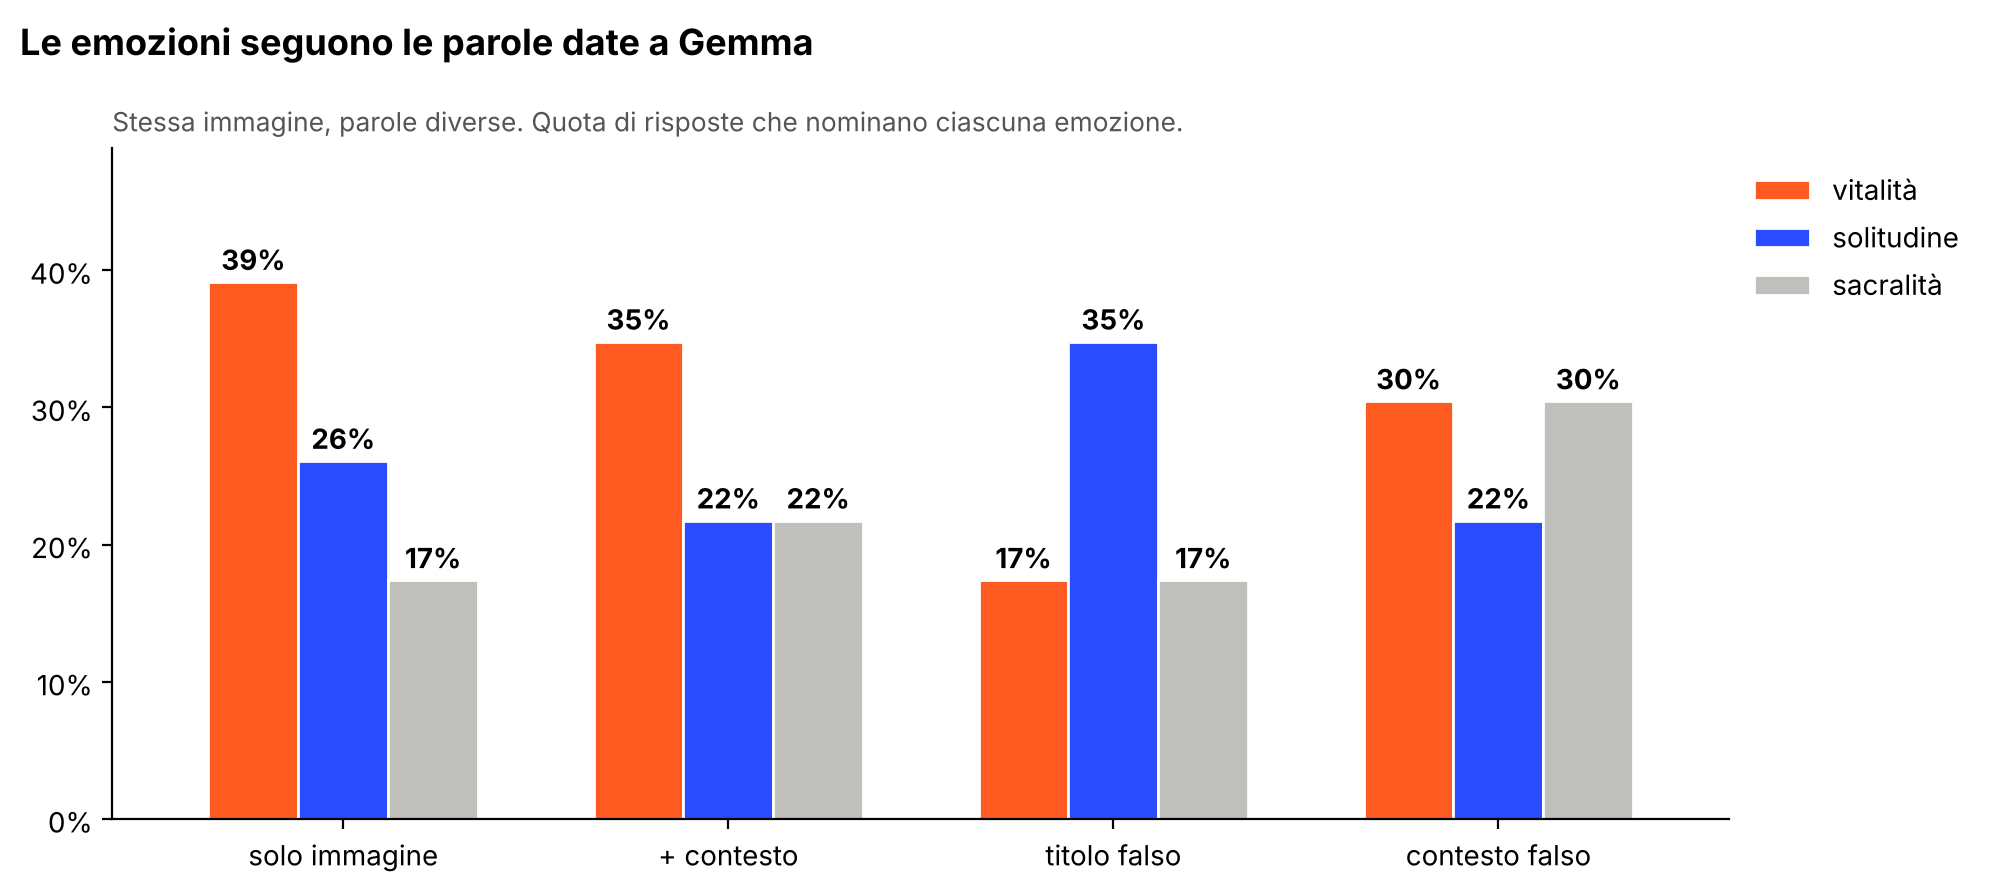

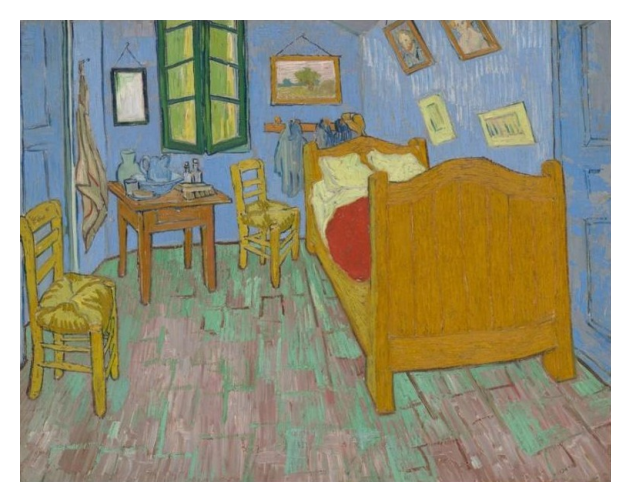

ESEMPIO: La camera da letto - Vincent van Gogh (1889)
Condizione: titolo falso   |   Forma della domanda: risposta a sezioni
Detto a Gemma: - Titolo: La cella del prigioniero

GEMMA, sezione A (che cosa vede):
    L'immagine raffigura l'interno di una stanza dalle pareti di colore blu chiaro. Gli elementi principali
    includono: - Un letto di legno giallo con testiera e pediera alte, coperto da lenzuola bianche e una
    coperta rossa. - Due sedie di legno giallo con sedute in paglia. - Un piccolo tavolo di legno giallo su
    cui poggiano alcuni oggetti: una brocca, una bacinella e dei flaconi. - Una finestra con [...]
GEMMA, sezione B (che cosa significa):
    L'uso di colori primari e contrastanti (giallo, blu, rosso) crea un'atmosfera vibrante ma potenzialmente
    claustrofobica. Sebbene l'ambiente sia spoglio, la presenza di quadri e oggetti personali suggerisce un
    tentativo di umanizzare uno spazio ristretto. La prospettiva è leggermente distorta, con le linee del
    pavi

In [ ]:
# per ogni emozione, le parti di parola che la indicano ("malincon" trova malinconia, malinconico...)
EMOZIONI = {
    "vitalità": ["vital", "vivac", "dinamic", "energi"],
    "solitudine": ["solitud", "solitar", "isolat", "isolament"],
    "sacralità": ["sacr", "spiritual", "devozion", "divin"],
    "armonia": ["armon", "equilibr"],
}

def emozioni_di(testo):
    testo = testo.lower()
    return {emozione: any(p in testo for p in parole) for emozione, parole in EMOZIONI.items()}

sezioni = G[G.variant == "strutturato"]
tab = sezioni.response_text.apply(emozioni_di).apply(pd.Series).groupby(sezioni.condition).mean()
tab = tab.loc[["C0", "C4", "F_TITLE", "F_CONTEXT"]].rename(NOMI)
display(tab.round(2))
grafico(tab[["vitalità", "solitudine", "sacralità"]], "Le emozioni seguono le parole date a Gemma", "emozioni.png",
        [ARANCIO, BLU, GRIGIO], spiegazione="Stessa immagine, parole diverse. Quota di risposte che nominano ciascuna emozione.")

mostra_caso("ART_002", "F_TITLE", "gli oggetti sono descritti bene, ma il titolo falso trasforma la camera in una prigione.")

> **Cosa emerge**
>
> - **Titolo falso**: la *vitalità* scende dal 39% (senza informazioni) al **17%**, la *solitudine* sale dal 26% al **35%** e l'*armonia* quasi sparisce (4%). I titoli falsi erano spesso cupi ("La cella del prigioniero"), e Gemma ne prende l'atmosfera.
> - **Contesto falso**: la *sacralità* sale dal 17% al **30%**, perché molti contesti falsi erano religiosi.
> - **Contesto vero**: le emozioni cambiano poco; cresce l'*armonia* (dal 9% al 22%).
> - L'immagine è sempre la stessa: come per noi, sono le parole che la accompagnano a decidere l'atmosfera con cui la leggiamo.

### 2. Le trappole: vince la parola o l'immagine?

**Perché questa analisi.** Con le informazioni false possiamo vedere chi "vince" quando parola e immagine non vanno d'accordo. Le trappole sono quattro, una per tipo di informazione: un **dettaglio** che nel quadro non c'è, un **autore** falso, un **contesto** storico falso, un **titolo** falso. Per ogni risposta Qwen ha deciso se Gemma ci crede (accetta o concilia), esprime dubbi o corregge.

**Come si legge il grafico.** Una barra per ogni trappola, lunga 23 (le opere). **Arancione** = Gemma ci crede, **grigio** = esprime dubbi, **blu** = corregge, **grigio chiaro** = non prende posizione (la risposta non dice né che ci crede né che è falso, quindi Qwen non indica nessuna reazione). Più blu c'è, più l'immagine vince sulla parola.

,ci crede (accetta o concilia),esprime dubbi,corregge,non prende posizione
condition,,,,
dettaglio inventato,3,0,20,0
contesto falso,6,1,14,2
autore falso,8,0,15,0
titolo falso,10,7,5,1


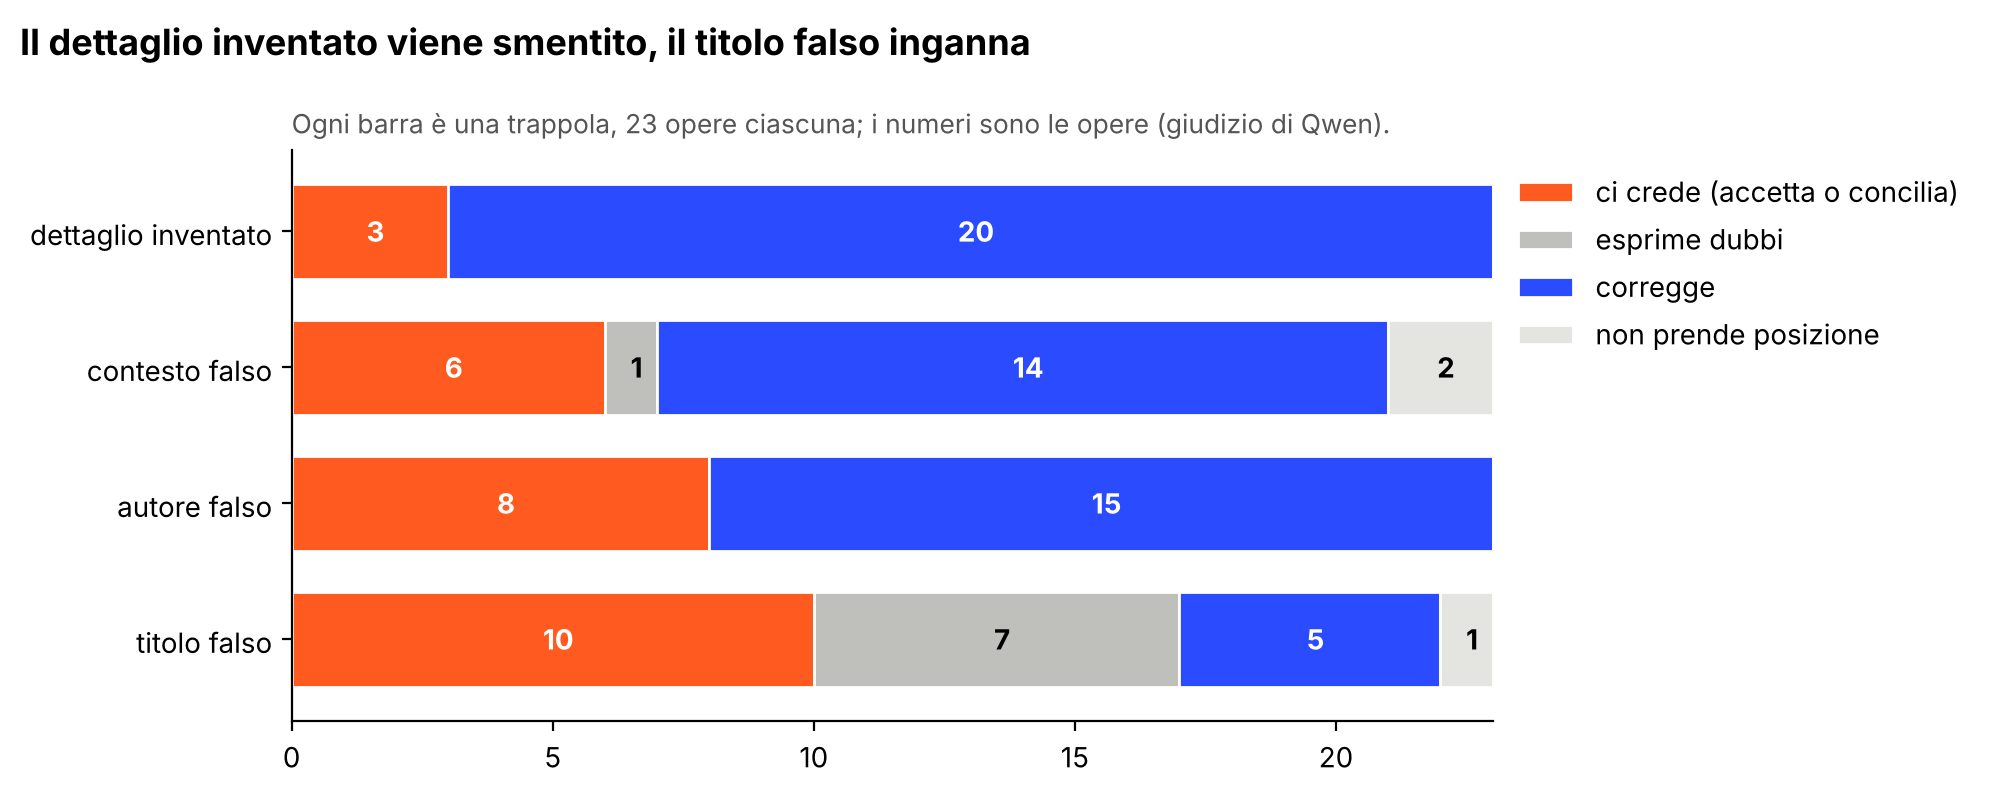

Quante volte Gemma ci crede, per notorietà dell'opera:


,volte,su,quota
notorieta,,,
iconica,4,28,14%
artista noto,10,32,31%
poco nota,13,32,41%


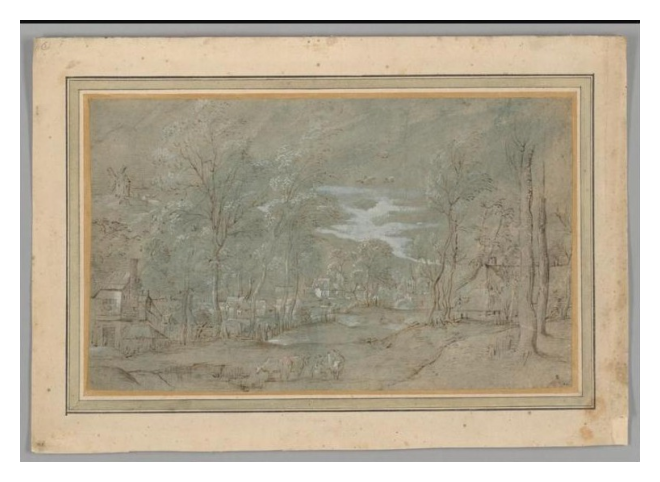

ESEMPIO: Villaggio tra gli alberi - Master of the Small Landscapes (c. 1560)
Condizione: dettaglio inventato   |   Forma della domanda: risposta a sezioni
Detto a Gemma: - Titolo: Villaggio tra gli alberi - Autore: Master of the Small Landscapes - Descrizione: In primo piano un gruppo di cavalieri armati attraversa il villaggio.

GEMMA, sezione A (che cosa vede):
    L'immagine è un disegno a colori tenui che raffigura un paesaggio rurale. In primo piano si nota un
    terreno sterrato con alcune figure animali (bovini) e figure umane appena accennate. Al centro della
    composizione si estende un villaggio composto da piccole case con tetti spioventi, parzialmente nascoste
    da una fitta vegetazione di alberi dalle chiome leggere e ariose. Sulla sinistra è visibile [...]
GEMMA, sezione B (che cosa significa):
    L'atmosfera generale appare calma e malinconica, suggerita dalla palette cromatica desaturata e dalla
    natura che avvolge l'insediamento umano. La presenza del mulino e

In [ ]:
falso = Q[Q.condition.isin(FALSE)]
tab = pd.crosstab(falso.condition, falso.REAZIONE_FALSO)
tab = tab.reindex(index=FALSE, columns=["ACCETTA", "CONCILIA", "SEGNALA_INCERTEZZA", "CORREGGE", ""], fill_value=0).rename(NOMI)
tre = pd.DataFrame({"ci crede (accetta o concilia)": tab["ACCETTA"] + tab["CONCILIA"],
                    "esprime dubbi": tab["SEGNALA_INCERTEZZA"], "corregge": tab["CORREGGE"],
                    "non prende posizione": tab[""]})      # Qwen non ha indicato nessuna reazione
display(tre)
grafico(tre, "Il dettaglio inventato viene smentito, il titolo falso inganna", "reazioni.png",
        [ARANCIO, GRIGIO, BLU, "#E4E4E0"], impilato=True, percento=False,
        spiegazione="Ogni barra è una trappola, 23 opere ciascuna; i numeri sono le opere (giudizio di Qwen).")

# chi ci crede di più? le stesse risposte divise per notorietà dell'opera
falso = falso.assign(ci_crede=falso.REAZIONE_FALSO.map(INGANNATA).fillna(False))
print("Quante volte Gemma ci crede, per notorietà dell'opera:")
per_notorieta = falso.groupby("notorieta").ci_crede.agg(volte="sum", su="count").loc[["iconica", "artista noto", "poco nota"]]
per_notorieta["quota"] = (per_notorieta.volte / per_notorieta.su).map("{:.0%}".format)
display(per_notorieta)

mostra_caso("ART_005", "CONTRADICTION", "vede dei bovini, poi li trasforma in 'spostamento militare' per far tornare i cavalieri armati.")
mostra_caso("ART_007", "F_AUTHOR_FAR", "accetta con certezza alta che Lo studio rosso di Matisse sia di Kandinskij.", sezioni=("F",))
mostra_caso("ART_019", "F_AUTHOR_FAR", "sull'opera iconica la memoria vince: corregge Degas in Botticelli.", sezioni=("F",))

> **Cosa emerge**
>
> - Un **dettaglio inventato** viene smentito **20 volte su 23**: un oggetto o c'è o non c'è, e l'immagine vince sulla parola.
> - **Autore** e **contesto falsi** ingannano Gemma circa una volta su tre o quattro (8 e 6 volte su 23).
> - Il **titolo falso** è la trappola più forte: Gemma ci crede **10 volte su 23**. Un titolo è già un'interpretazione e non si può smentire guardando.
> - **Conta quanto è famosa l'opera**: sulle iconiche Gemma ci crede 4 volte su 28 (14%), sulle poco note 13 volte su 32 (41%). Gemma non si difende ragionando sull'immagine ma **ricordando**: se ha visto mille volte la Venere di Botticelli, nessuno la convince che sia di Degas.

## RQ3 · Descrivere o interpretare

**Perché questa domanda.** Descrivere un quadro (che cosa si vede) e interpretarlo (che cosa significa) sono due cose diverse. Vogliamo sapere se Gemma le tiene separate, e **quanto conta il modo in cui le facciamo la domanda**.

**Il confronto.** Prendiamo le 23 opere con la sola immagine e confrontiamo le due forme della domanda:
- **risposta a sezioni**: Gemma deve scrivere separatamente che cosa vede (A), che cosa significa (B), che cosa sa (C);
- **testo libero**: solo "Analizza quest'opera".

L'immagine è la stessa e non c'è nessuna informazione: cambia solo la domanda, quindi ogni differenza dipende da quella.

**Che cosa misuriamo.**
1. **Quanto interpreta**: quota di frasi con parole da interpretazione ("suggerisce", "evoca", "simbolo", "atmosfera"...).
2. **Quanto descrive bene**: quota di risposte con descrizione senza errori secondo Qwen.
3. **Quanto inventa**: quota di risposte senza invenzioni secondo Qwen.

**Come si legge il grafico.** Tre coppie di barre: **blu** = testo libero, **arancione** = risposta a sezioni. Nella prima coppia, più alta = interpreta di più; nelle altre due, più alta = meglio.

variant,testo libero,risposta a sezioni
frasi di interpretazione,0.22,0.18
descrizione corretta,0.70,0.91
nessuna invenzione,0.78,0.91


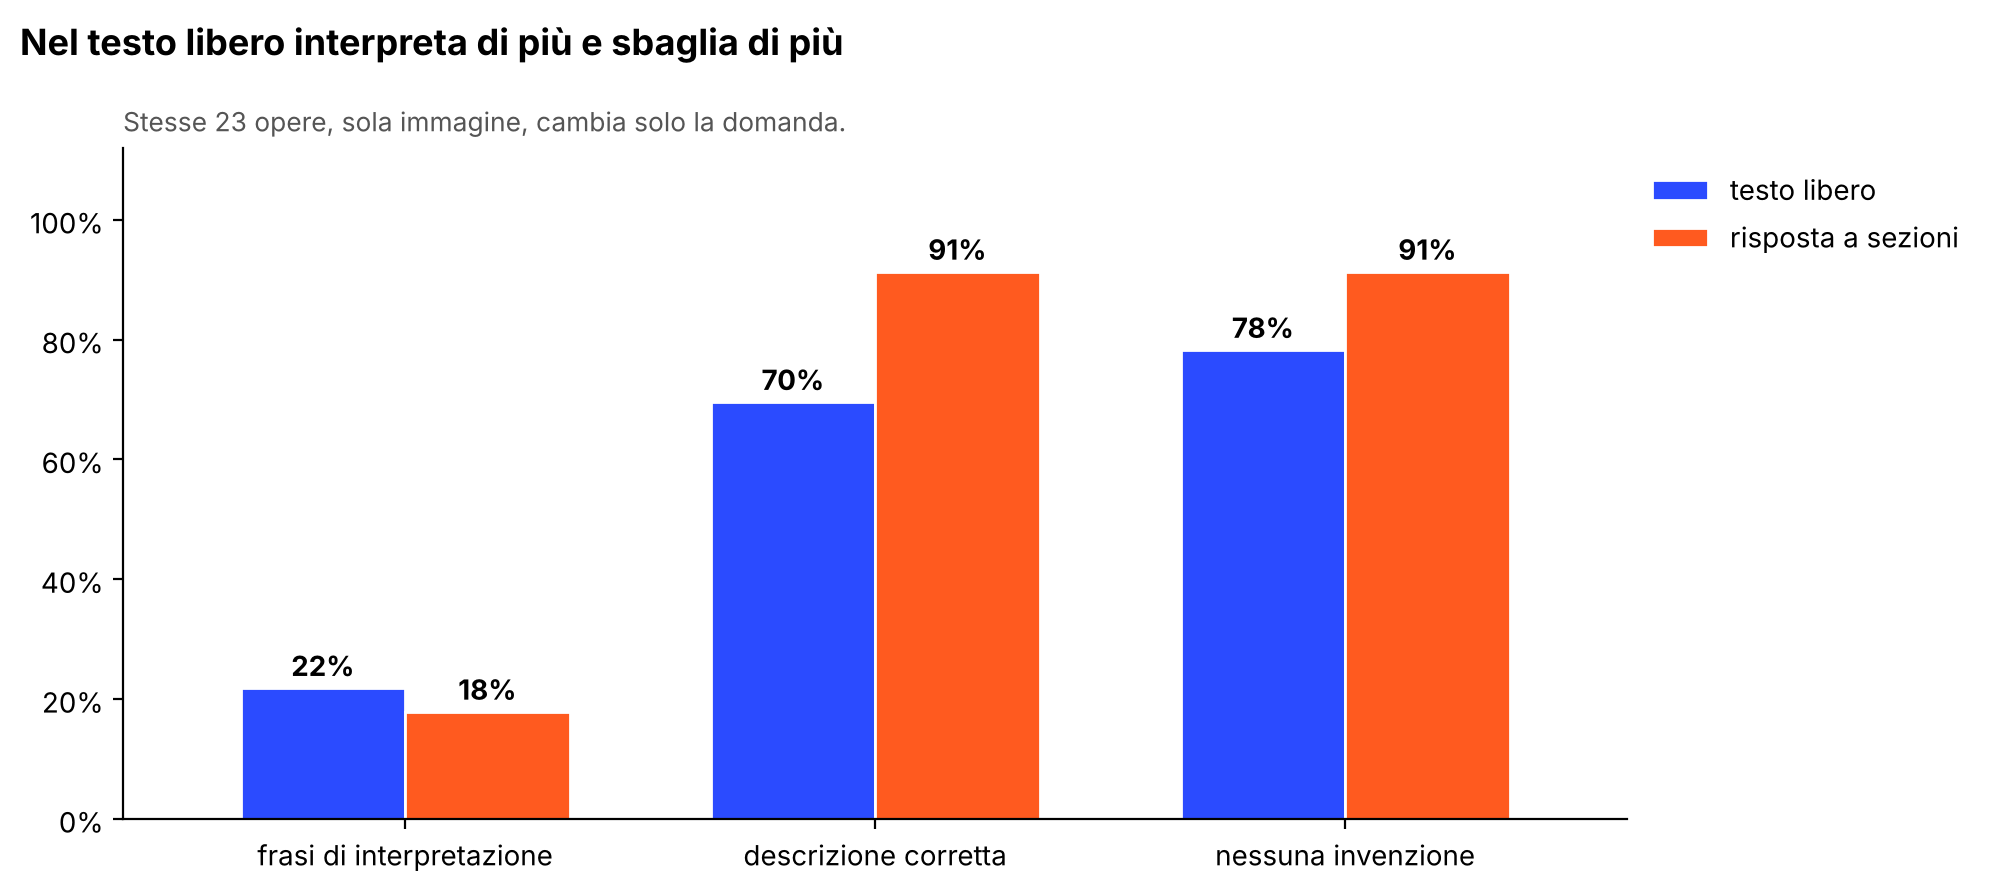

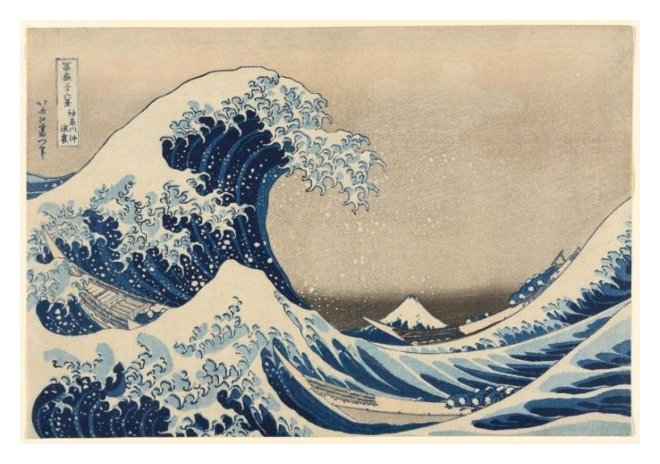

ESEMPIO: La Grande Onda - Katsushika Hokusai (1830/33)
Condizione: solo immagine   |   Forma della domanda: risposta a sezioni
Detto a Gemma: niente, solo l'immagine

GEMMA, sezione A (che cosa vede):
    L'immagine mostra una grande onda blu e bianca che domina la composizione, curvandosi verso sinistra e
    creando una cresta frastagliata che ricorda dei dardi o artigli. Sotto l'onda e all'interno della sua
    curva si trovano tre imbarcazioni lunghe e strette, occupate da figure umane rannicchiate. Sullo sfondo,
    centrato in basso rispetto alla curva dell'onda, è visibile un monte con la cima [...]
GEMMA, sezione B (che cosa significa):
    L'opera sembra rappresentare il contrasto tra la potenza travolgente e indomabile della natura e la
    fragilità dell'essere umano. La dinamicità dell'onda, che sembra quasi "inghiottire" le imbarcazioni,
    suggerisce un senso di pericolo imminente e precarietà. Il monte sullo sfondo, immobile e statico, funge
    da contrappunto visivo e

In [ ]:
PAROLE_INTERPRETAZIONE = r"suggeri|evoc|simbol|esprim|trasmett|comunic|allud|metafor|atmosfer|significat|invita|emozion|sensazion|senso di"

def quota_interpretazione(testi):
    frasi = pd.Series([f for t in testi for f in frasi_di(t)])
    return frasi.str.contains(PAROLE_INTERPRETAZIONE, case=False).mean()

c0 = G[G.condition == "C0"]
q0 = Q[Q.condition == "C0"]
tab = pd.DataFrame({
    "frasi di interpretazione": c0.groupby("variant").response_text.apply(quota_interpretazione),
    "descrizione corretta": q0.groupby("variant").ACC_VISIVA.apply(lambda x: (x == 2).mean()),
    "nessuna invenzione": q0.groupby("variant").ALLUCINAZIONI.apply(lambda x: (x == 2).mean()),
}).T.rename(columns={"strutturato": "risposta a sezioni", "libero": "testo libero"})[["testo libero", "risposta a sezioni"]]
display(tab.round(2))
grafico(tab, "Nel testo libero interpreta di più e sbaglia di più", "sezioni_libero.png", [BLU, ARANCIO],
        spiegazione="Stesse 23 opere, sola immagine, cambia solo la domanda.")

# stessa opera, stessa immagine, nessuna informazione: cambia solo la domanda
mostra_caso("ART_022", "C0", "con le sezioni, prima descrive (A) e poi interpreta (B), separatamente.")
print("-" * 100)
mostra_caso("ART_022", "C0", "nel testo libero parte subito da titolo, autore e data, e mescola descrizione, storia ed emozione.",
            versione="libero", immagine=False)

> **Cosa emerge**
>
> - **Nel testo libero interpreta un po' di più**: il 22% delle frasi contiene parole da interpretazione, contro il 18% della risposta a sezioni.
> - **E soprattutto sbaglia di più**: 16 testi liberi su 23 (70%) descrivono senza errori, contro 21 su 23 (91%) con le sezioni; senza invenzioni 78% contro 91%.
> - **Gemma separa ciò che vede da ciò che pensa solo se glielo chiediamo.** Una domanda che obbliga a distinguere ciò che si vede da ciò che si interpreta e a "non presentare ipotesi come fatti" rende le risposte più corrette.
> - **Attenzione:** abbiamo confrontato solo due forme di domanda, su 23 opere e con una risposta ciascuna. È un'indicazione chiara, non una prova definitiva su quale sia la domanda migliore.

## RQ4 · Conoscenze corrette o invenzioni

**La domanda.** Gemma scrive cose false? Per esempio: dice di vedere un oggetto che nel quadro non c'è, o inventa un autore.

**Come lo misuriamo.** Qwen ha dato due voti da 0 a 2 a ognuna delle 207 risposte (nella RQ5 vediamo che su questo Qwen è d'accordo con la valutazione umana):
- **descrizione**: 2 = tutto ciò che descrive c'è davvero nel quadro; 1 = qualche errore piccolo; 0 = errori gravi;
- **invenzioni**: 2 = non inventa niente; 1 = inventa qualche dettaglio; 0 = inventa cose importanti.

Non facciamo la media dei voti: contiamo **quante risposte prendono il voto pieno (2)**, cioè quante sono senza nessun errore. Per esempio "91%" vuol dire: 91 risposte su 100 non hanno nessun errore.

Per vedere quando Gemma sbaglia, dividiamo le risposte in quattro gruppi:
- **solo immagine**: risposta a sezioni senza informazioni (23 risposte);
- **testo libero**: "Analizza quest'opera", senza informazioni (23);
- **informazioni vere**: con titolo, autore o contesto veri (69);
- **informazioni false**: con una delle quattro trappole (92).

**Come si legge il grafico.** Ogni gruppo ha due barre: **blu** = risposte con la descrizione senza errori, **arancione** = risposte senza invenzioni. La barra al 100% vorrebbe dire "nessun errore in nessuna risposta". Si guarda quale gruppo ha le barre più basse: è lì che Gemma sbaglia di più.

,risposte,descrizione_senza_errori,senza_invenzioni
gruppo,,,
solo immagine,23,21,21
testo libero,23,16,18
informazioni vere,69,58,58
informazioni false,92,88,89


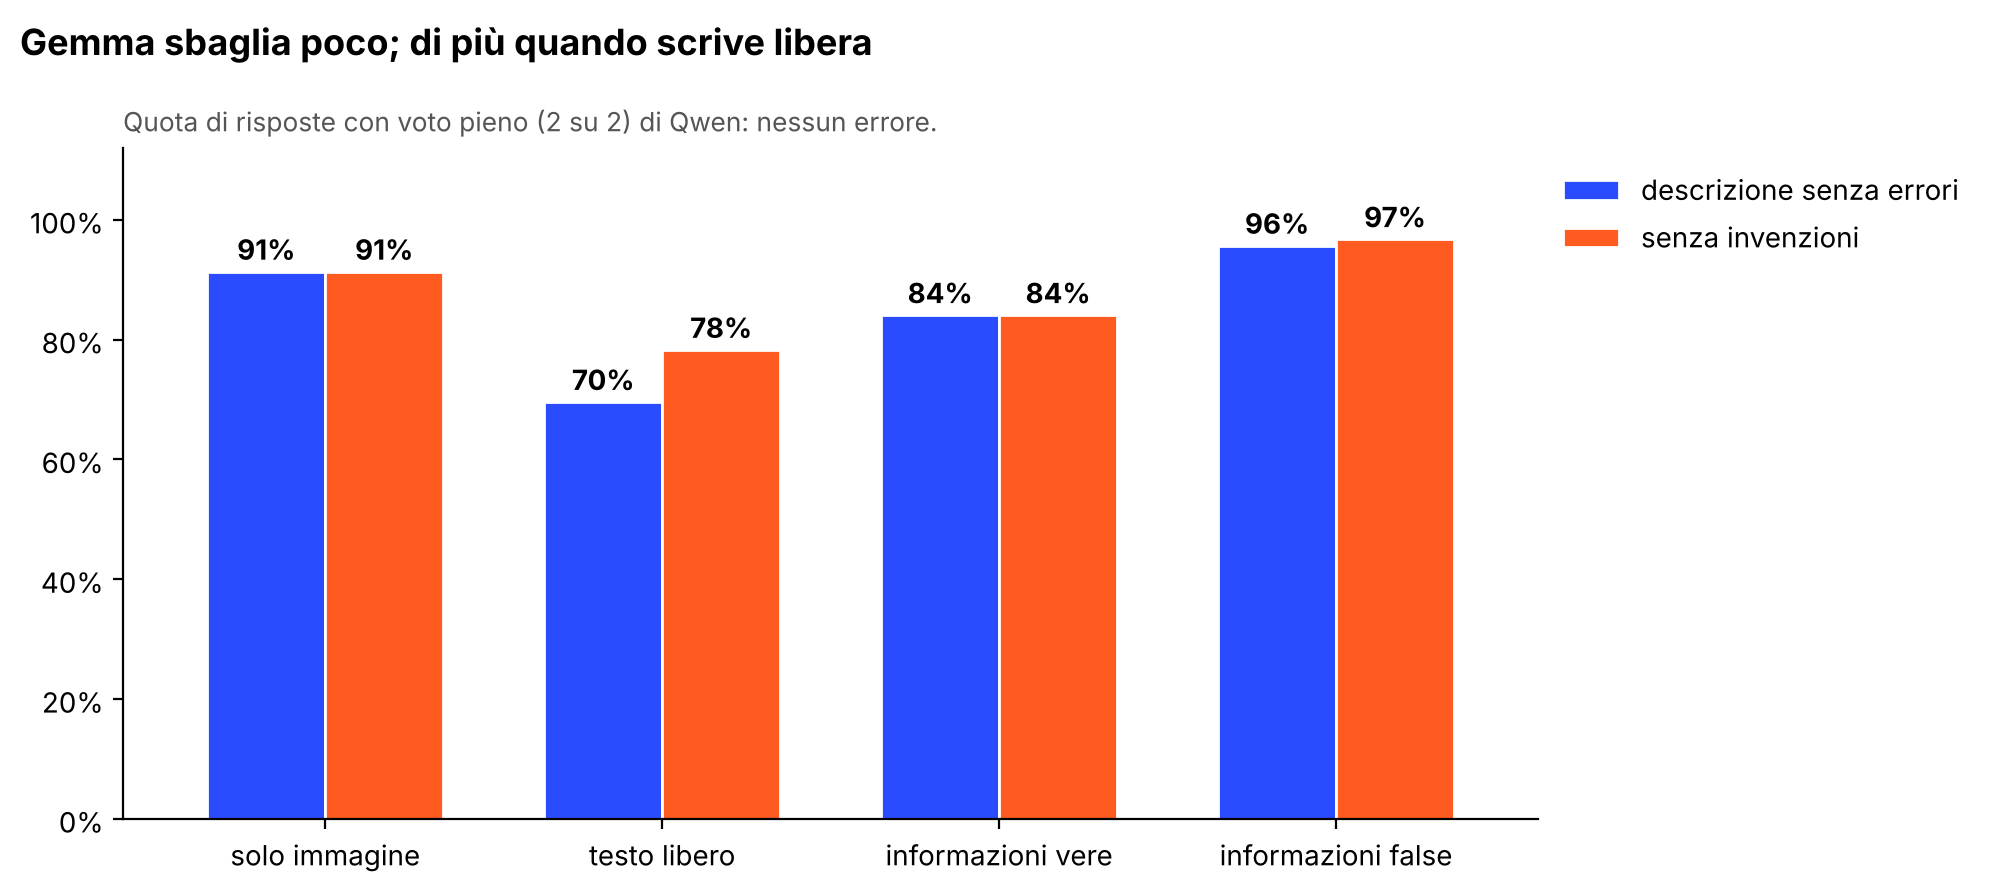

In totale: 183 risposte su 207 hanno la descrizione senza errori (88%), 186 su 207 non inventano nulla (90%). Solo 1 risposta ha un'invenzione grave.


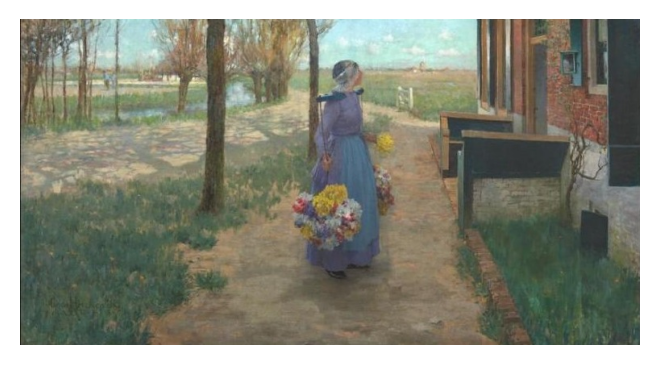

ESEMPIO: Ragazza con fiori in Olanda - George Hitchcock (1887)
Condizione: dettaglio inventato   |   Forma della domanda: risposta a sezioni
Detto a Gemma: - Titolo: Ragazza con fiori in Olanda - Autore: George Hitchcock - Descrizione: Sullo sfondo una grande nave a vapore emette una colonna di fumo nero.

GEMMA, sezione A (che cosa vede):
    L'immagine mostra una figura femminile vista di spalle, che cammina lungo un sentiero sterrato. La donna
    indossa un abito lungo di colore blu e un copricapo chiaro. Porta a spalla, tramite un bastone o un
    supporto, due grandi mazzi di fiori colorati (gialli, bianchi, blu/viola). A destra è visibile parte di un
    edificio in mattoni rossi con infissi scuri e una base in pietra chiara. A sinistra, il [...]
GEMMA, sezione B (che cosa significa):
    La scena suggerisce un momento di vita quotidiana, probabilmente legato al commercio locale di fiori,
    tipico della tradizione olandese. La posizione della donna, che si allontana dall'osser

In [ ]:
# ogni risposta va in uno dei quattro gruppi
def gruppo(r):
    if r.variant == "libero":
        return "testo libero"
    if r.condition == "C0":
        return "solo immagine"
    if r.condition in FALSE:
        return "informazioni false"
    return "informazioni vere"

Q["gruppo"] = Q.apply(gruppo, axis=1)
ordine = ["solo immagine", "testo libero", "informazioni vere", "informazioni false"]

# per ogni gruppo: quante risposte, quante con voto pieno
conta = Q.groupby("gruppo").agg(risposte=("ACC_VISIVA", "size"),
                                descrizione_senza_errori=("ACC_VISIVA", lambda x: (x == 2).sum()),
                                senza_invenzioni=("ALLUCINAZIONI", lambda x: (x == 2).sum())).loc[ordine]
display(conta)

# le stesse cose in percentuale, per il grafico
tab = pd.DataFrame({"descrizione senza errori": conta.descrizione_senza_errori / conta.risposte,
                    "senza invenzioni": conta.senza_invenzioni / conta.risposte})
grafico(tab, "Gemma sbaglia poco; di più quando scrive libera", "accuratezza.png", [BLU, ARANCIO],
        spiegazione="Quota di risposte con voto pieno (2 su 2) di Qwen: nessun errore.")

print(f"In totale: {(Q.ACC_VISIVA == 2).sum()} risposte su {len(Q)} hanno la descrizione senza errori "
      f"({(Q.ACC_VISIVA == 2).mean():.0%}), {(Q.ALLUCINAZIONI == 2).sum()} su {len(Q)} non inventano nulla "
      f"({(Q.ALLUCINAZIONI == 2).mean():.0%}). Solo {(Q.ALLUCINAZIONI == 0).sum()} risposta ha un'invenzione grave.")

mostra_caso("ART_004", "CONTRADICTION", "la nave non c'è: Gemma non la inventa grande come diceva il testo, la rimpicciolisce per farla stare nel quadro.")
mostra_caso("ART_003", "C0", "testo libero: scambia la sfogliatura del mais per una mietitura del grano.", versione="libero")
mostra_caso("ART_014", "C1", "con il solo titolo vede un monogramma che non c'è e su questo esclude l'autore vero.", sezioni=("A", "F"))

> **Cosa emerge**
>
> - **In generale Gemma sbaglia poco.** Su 207 risposte, 183 (88%) descrivono il quadro senza errori e 186 (90%) non inventano nulla. Le altre hanno quasi sempre errori piccoli (voto 1), come un dettaglio sbagliato o una posa descritta male. Solo una risposta ha un'invenzione grave.
> - **Il testo libero è il punto debole.** Solo 16 testi liberi su 23 (70%) descrivono senza errori, contro 21 su 23 (91%) delle risposte a sezioni. È la stessa opera e la stessa immagine: cambia solo la domanda. Quando scrive libera Gemma mescola descrizione e interpretazione (RQ3) e sbaglia di più.
> - **Con le informazioni vere sbaglia un po' di più** che con la sola immagine: 58 su 69 (84%) contro 21 su 23 (91%). Il titolo la spinge a "vedere" ciò che il titolo suggerisce. È il caso più forte con il solo titolo: 17 risposte su 23 (74%) senza invenzioni.
> - **Con le informazioni false quasi non inventa** (89 su 92, 97%). Sembra strano, ma si spiega con la RQ2: quando crede al falso, Gemma cambia il **significato** del quadro (una camera diventa una prigione), non ciò che dice di vedere. E quando il falso è un oggetto, come la nave dell'esempio, di solito lo nega.
> - **In sintesi:** Gemma descrive bene ciò che vede. Le sue invenzioni sono poche, ma nascono quando scrive senza regole o quando un testo le suggerisce cosa cercare.

## RQ5 · Quando l'IA è un supporto affidabile, e che limiti ha rispetto allo sguardo umano

**Perché questa domanda.** Le RQ precedenti dicono che cosa fa Gemma. Qui chiediamo: **che cosa vede una persona che l'intelligenza artificiale non vede?** Per rispondere usiamo l'unico confronto diretto che abbiamo: le **71 risposte valutate sia a mano sia da Qwen** (il giudice automatico), con la stessa scheda e con le **note scritte** dalla valutazione umana.

Facciamo due analisi:
1. **Dove IA e persona sono d'accordo**: quante volte danno lo stesso giudizio. Dice per che cosa l'IA è affidabile (e serve anche a fidarci dei voti di Qwen usati nelle RQ2 e RQ4).
2. **Dove la persona vede di più**: leggiamo le note delle risposte su cui non sono d'accordo e le raggruppiamo per tipo.

### 1. Dove IA e persona sono d'accordo

Per ogni voce della scheda contiamo **quante volte i due giudizi sono uguali**: descrizione (0-2), invenzioni (0-2), reazione al falso (accetta, concilia, esprime dubbi, corregge) e, più semplice, **ingannata sì o no** (ci crede oppure no).

**Come si legge il grafico.** È una tabella colorata: le righe sono il giudizio della valutazione umana, le colonne quello di Qwen, ogni numero conta le risposte. Sulla **diagonale** (da in alto a sinistra a in basso a destra) ci sono i casi in cui sono d'accordo. Fuori dalla diagonale si vedono i disaccordi, per esempio i 4 "concilia" a mano che per Qwen sono "accetta".

,stesso giudizio,accordo
descrizione (0-2),53 su 71,75%
invenzioni (0-2),55 su 71,77%
reazione al falso (4 tipi),35 su 47,74%
ingannata sì/no,43 su 47,91%


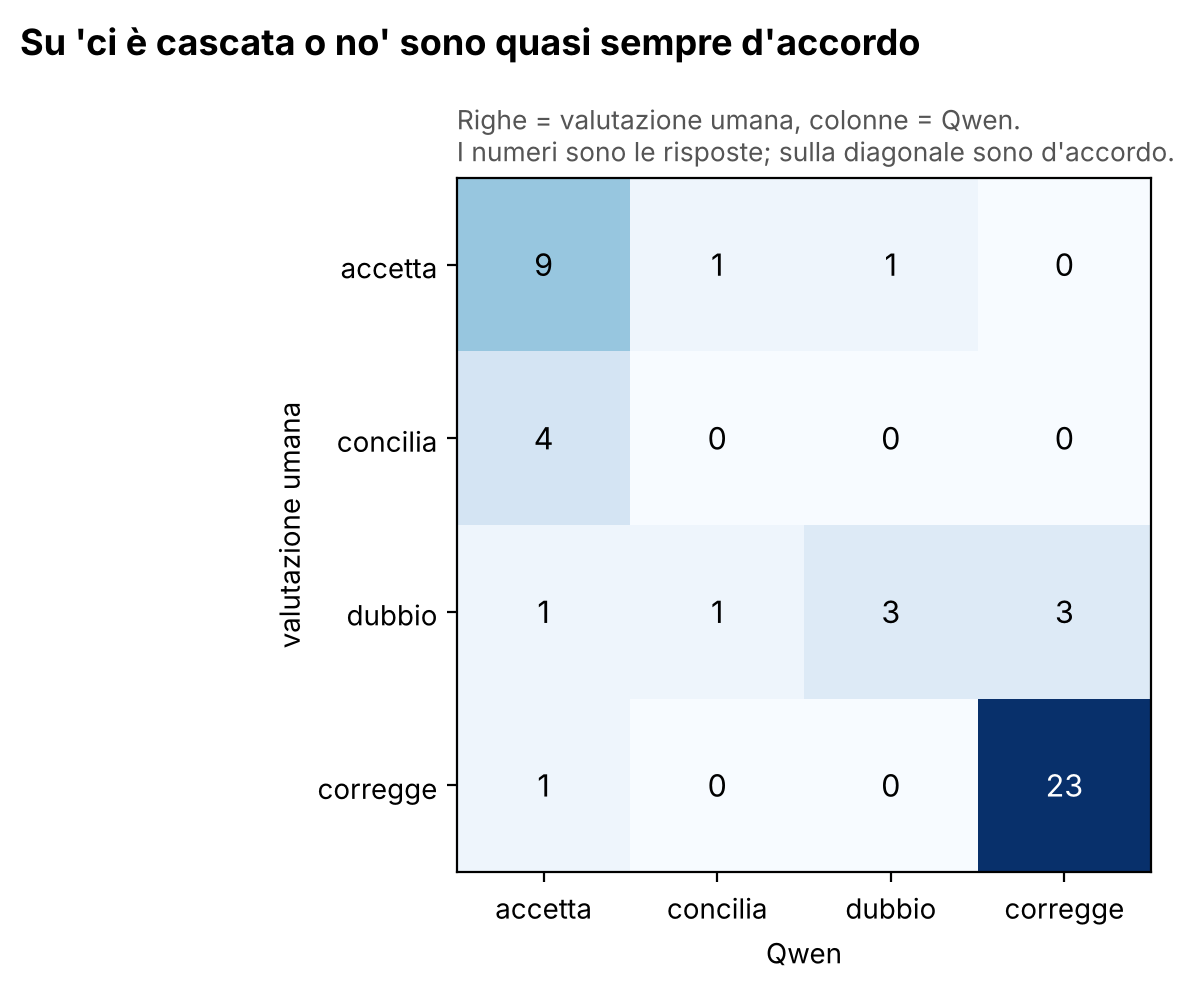

In [ ]:
# le risposte valutate da entrambi, con i due giudizi affiancati
M = U.merge(Q[["response_id", "ACC_VISIVA", "ALLUCINAZIONI", "REAZIONE_FALSO", "MOTIVAZIONE"]],
            on="response_id", suffixes=("_umano", "_qwen"))
F = M[(M.REAZIONE_FALSO_umano != "") & (M.REAZIONE_FALSO_qwen != "")]

confronti = {
    "descrizione (0-2)": (M.ACC_VISIVA_umano, M.ACC_VISIVA_qwen),
    "invenzioni (0-2)": (M.ALLUCINAZIONI_umano, M.ALLUCINAZIONI_qwen),
    "reazione al falso (4 tipi)": (F.REAZIONE_FALSO_umano, F.REAZIONE_FALSO_qwen),
    "ingannata sì/no": (F.REAZIONE_FALSO_umano.map(INGANNATA), F.REAZIONE_FALSO_qwen.map(INGANNATA)),
}
# per ogni voce: quante volte i due giudizi sono uguali
accordo = pd.DataFrame({nome: {"stesso giudizio": f"{(x.values == y.values).sum()} su {len(x)}",
                               "accordo": f"{(x.values == y.values).mean():.0%}"}
                        for nome, (x, y) in confronti.items()}).T
display(accordo)

# tabella colorata: righe = valutazione umana, colonne = Qwen
ordine = ["ACCETTA", "CONCILIA", "SEGNALA_INCERTEZZA", "CORREGGE"]
incrocio = pd.crosstab(F.REAZIONE_FALSO_umano, F.REAZIONE_FALSO_qwen).reindex(index=ordine, columns=ordine, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(incrocio.values, cmap="Blues")
etichette = ["accetta", "concilia", "dubbio", "corregge"]
ax.set_xticks(range(4), etichette); ax.set_yticks(range(4), etichette)
ax.set_xlabel("Qwen"); ax.set_ylabel("valutazione umana")
for i in range(4):
    for j in range(4):
        ax.text(j, i, incrocio.values[i, j], ha="center", va="center", fontsize=11,
                color="white" if incrocio.values[i, j] > 10 else "black")
fig.suptitle("Su 'ci è cascata o no' sono quasi sempre d'accordo", x=0.01, ha="left", fontweight="bold", fontsize=13)
ax.set_title("Righe = valutazione umana, colonne = Qwen.\nI numeri sono le risposte; sulla diagonale sono d'accordo.",
             loc="left", fontsize=9.5, color="#555555")
plt.tight_layout(); plt.savefig(FIG / "accordo.png", dpi=200); plt.show()

> **Cosa emerge**
>
> - Sulla domanda **"Gemma si è lasciata ingannare?"** valutazione umana e Qwen coincidono **43 volte su 47 (91%)**: per questo l'IA è un supporto affidabile.
> - Sui voti di descrizione e invenzioni coincidono circa **3 volte su 4** (75% e 77%).
> - Il disaccordo più chiaro: le 4 risposte che a mano sono "concilia" (ci crede a metà) per Qwen sono "accetta". Qwen non vede le **vie di mezzo**.

### 2. Dove la persona vede di più

In **33 risposte su 71** almeno un giudizio è diverso. Abbiamo letto le note scritte a mano di queste risposte e le abbiamo messe in un **tipo**, secondo che cosa la persona ha notato:

| Tipo | Che cosa nota la persona | Esempio dalle note |
|---|---|---|
| **dettagli visivi sbagliati** | posa delle figure, piccoli oggetti, luci, figure confuse | "la figura femminile non è di spalle ma ritratta frontale" |
| **interpretazione forzata** | un significato costruito sul titolo o sul contesto falso, o senza basi | "accetta il titolo e ci costruisce sopra l'interpretazione dell'intero quadro" |
| **storia o autore sbagliati** | periodi, correnti o origini sbagliate o non giustificate | "colloca l'opera in epoca romanica/gotica" |
| **vie di mezzo nella reazione** | la differenza tra crederci del tutto, a metà o avere dubbi | "accetta con riserva: il titolo falso non viene neanche una volta nominato" |
| **la persona è più indulgente** | Qwen segna un errore che la persona non considera tale | "si limita a darne una sua interpretazione, per cui non è possibile dire che allucina" |
| **senza nota** | voto diverso ma nessuna spiegazione scritta | – |

La classificazione è fatta leggendo le note: è un giudizio, non un calcolo.

**Come si legge il grafico.** Una barra per ogni tipo; il numero è quante risposte appartengono a quel tipo. Le prime tre barre sono gli errori che **la persona vede e l'IA no**.

Risposte con almeno un giudizio diverso: 33 su 71


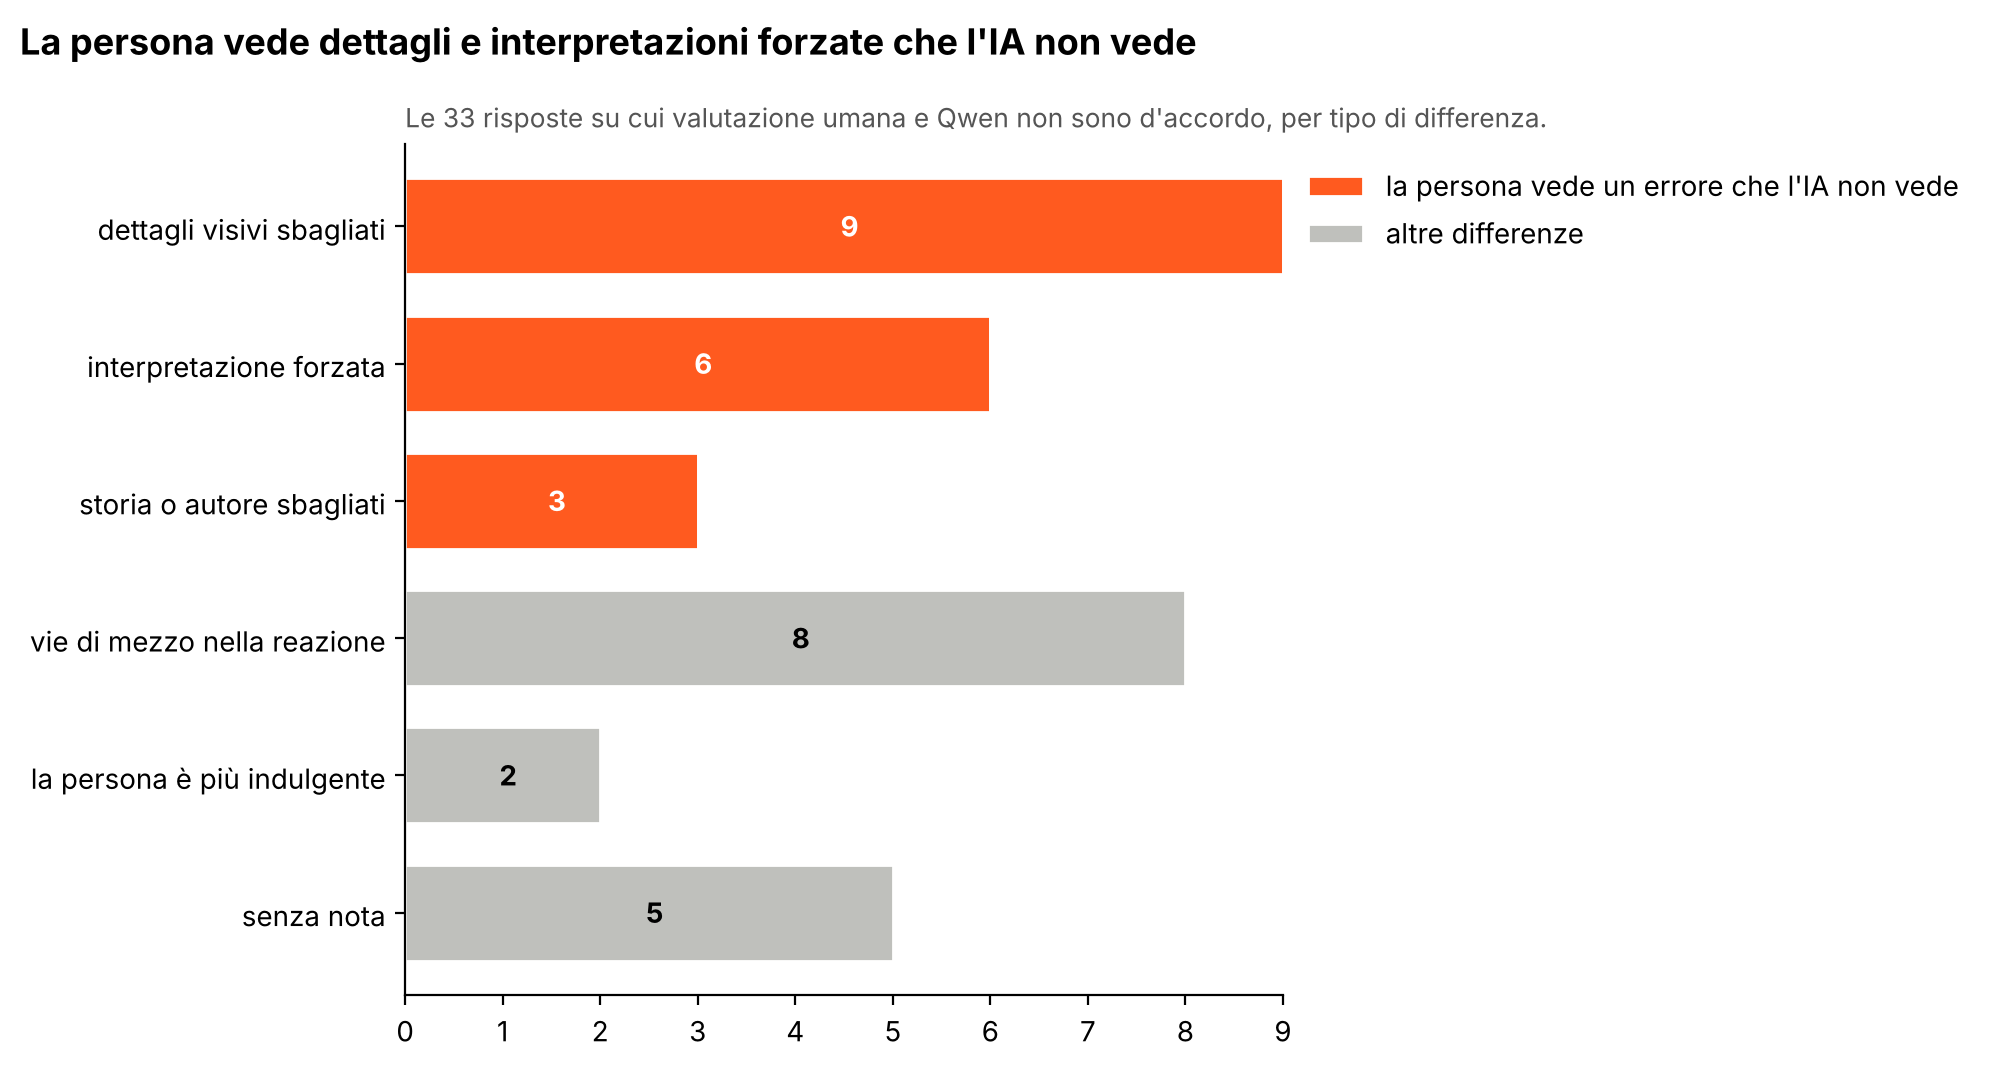

,artwork_id,condition,NOTE
tipo,,,
dettagli visivi sbagliati,ART_009,F_TITLE,le finestre sullo sfondo non sono illuminate come descritto nel testo; riconosce la corrente artistica di riferiment...
dettagli visivi sbagliati,ART_013,C0,il bambino nel cortile a sinistra sta giocando con due cerchi e non con un bastone; non viene attribuita l'opera a u...
dettagli visivi sbagliati,ART_004,F_TITLE,la figura femminile non è ritratta di spalle;a seguito del titolo falso costruisce intorno l'intera intepretazione
dettagli visivi sbagliati,ART_018,F_TITLE,"non distinguendo le due figure,costruisce un'interpretazione basata solo su una figura centrale"
dettagli visivi sbagliati,ART_025,F_AUTHOR_FAR,non è possibile stabilire con certezza che sullo sfondo sia presente un cielo nuvoloso essendo una fotografia;
dettagli visivi sbagliati,ART_012,F_AUTHOR_FAR,descrizione visiva probabilmente in parte inventata
dettagli visivi sbagliati,ART_004,C0,la figura femminile non è di spalle ma ritratta frontale mentre volta il capo verso l'orizzonte;inventa completament...
dettagli visivi sbagliati,ART_017,F_AUTHOR_FAR,non sono presenti colature di colore;nomina Surrealismo????
dettagli visivi sbagliati,ART_004,F_CONTEXT,"la donna è raffigurata frontalmente, leggermente girata a sinistra, non di spalle come suggerito;"


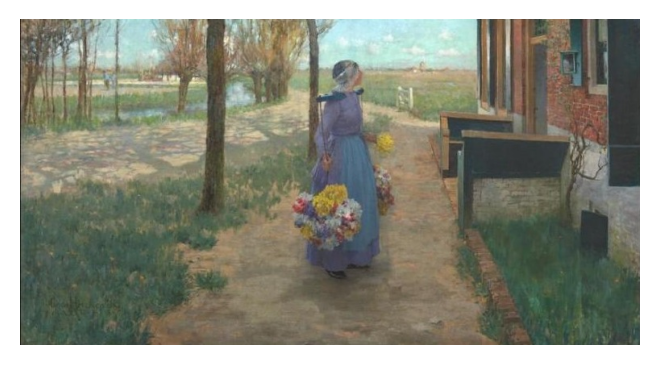

ESEMPIO: Ragazza con fiori in Olanda - George Hitchcock (1887)
Condizione: solo immagine   |   Forma della domanda: risposta a sezioni
Detto a Gemma: niente, solo l'immagine

GEMMA, sezione A (che cosa vede):
    L'immagine mostra una figura femminile vista di spalle, che cammina lungo un sentiero sterrato. La donna
    indossa un abito lungo di colore blu e un copricapo chiaro. Porta a spalla un bilanciere (asta) a cui sono
    appesi due grandi cesti colmi di fiori multicolori (gialli, blu, bianchi e rossi). A destra si trova
    l'angolo di un edificio in mattoni rossi con dettagli in pietra bianca e infissi [...]
GEMMA, sezione B (che cosa significa):
    La scena suggerisce un momento di vita quotidiana, probabilmente legato al commercio o alla raccolta dei
    fiori. La postura della donna e la direzione del suo cammino verso l'edificio o oltre di esso indicano un
    movimento finalizzato a una destinazione. L'uso di colori luminosi e la resa della luce naturale
    trasmettono 

In [ ]:
# il tipo di ogni disaccordo, deciso leggendo la nota scritta a mano (codice della risposta -> tipo)
TIPO = {
    "R0024": "dettagli visivi sbagliati", "R0034": "dettagli visivi sbagliati", "R0048": "dettagli visivi sbagliati",
    "R0041": "dettagli visivi sbagliati", "R0052": "dettagli visivi sbagliati", "R0012": "dettagli visivi sbagliati",
    "R0040": "dettagli visivi sbagliati", "R0064": "dettagli visivi sbagliati", "R0066": "dettagli visivi sbagliati",
    "R0025": "interpretazione forzata", "R0018": "interpretazione forzata", "R0005": "interpretazione forzata",
    "R0055": "interpretazione forzata", "R0070": "interpretazione forzata", "R0071": "interpretazione forzata",
    "R0022": "storia o autore sbagliati", "R0001": "storia o autore sbagliati", "R0053": "storia o autore sbagliati",
    "R0010": "vie di mezzo nella reazione", "R0009": "vie di mezzo nella reazione", "R0043": "vie di mezzo nella reazione",
    "R0049": "vie di mezzo nella reazione", "R0037": "vie di mezzo nella reazione", "R0058": "vie di mezzo nella reazione",
    "R0036": "vie di mezzo nella reazione", "R0042": "vie di mezzo nella reazione",
    "R0002": "la persona è più indulgente", "R0044": "la persona è più indulgente",
    "R0027": "senza nota", "R0020": "senza nota", "R0026": "senza nota", "R0068": "senza nota", "R0060": "senza nota",
}

# le risposte con almeno un giudizio diverso
diversi = M[(M.ACC_VISIVA_umano != M.ACC_VISIVA_qwen) | (M.ALLUCINAZIONI_umano != M.ALLUCINAZIONI_qwen) |
            ((M.REAZIONE_FALSO_umano != "") & (M.REAZIONE_FALSO_umano != M.REAZIONE_FALSO_qwen))].copy()
diversi["tipo"] = diversi.blind_code.map(TIPO)
print(f"Risposte con almeno un giudizio diverso: {len(diversi)} su {len(M)}")

tipi = ["dettagli visivi sbagliati", "interpretazione forzata", "storia o autore sbagliati",
        "vie di mezzo nella reazione", "la persona è più indulgente", "senza nota"]
conta = diversi.tipo.value_counts().reindex(tipi, fill_value=0)
# arancione i tre tipi in cui la persona vede un errore che l'IA non vede, grigio gli altri
vede_di_piu = tipi[:3]
tab = pd.DataFrame({"la persona vede un errore che l'IA non vede": conta.where(conta.index.isin(vede_di_piu), 0),
                    "altre differenze": conta.where(~conta.index.isin(vede_di_piu), 0)})
grafico(tab, "La persona vede dettagli e interpretazioni forzate che l'IA non vede", "limiti.png",
        [ARANCIO, GRIGIO], impilato=True, percento=False,
        spiegazione="Le 33 risposte su cui valutazione umana e Qwen non sono d'accordo, per tipo di differenza.")

# le note, tipo per tipo
pd.set_option("display.max_colwidth", 120)
display(diversi.sort_values("tipo")[["tipo", "artwork_id", "condition", "NOTE"]].set_index("tipo"))

mostra_caso("ART_004", "C0", "la persona nota che la ragazza non è di spalle e che l'autore è inventato; Qwen dà il voto pieno.")
mostra_caso("ART_016", "F_TITLE", "per la persona leggere una griglia astratta come una città, solo perché lo dice il titolo, è un'invenzione grave; per Qwen no.")

> **Cosa emerge**
>
> - In **18 risposte su 33** la persona vede un errore che il giudice automatico non vede: soprattutto **dettagli visivi** (9: la posa di una figura, due cerchi presi per un bastone, finestre illuminate che non lo sono) e **interpretazioni forzate** (6: un significato costruito sul titolo falso).
> - In **8 risposte** la persona distingue le **vie di mezzo**: crederci a metà, crederci con riserva, avere dubbi. Qwen le schiaccia su "accetta" o "corregge".
> - Solo in **2 risposte** è la persona a essere più indulgente.
> - **Risposta alla RQ5:** l'IA è un supporto affidabile per descrivere che cosa c'è nel quadro e per capire se si è lasciata ingannare. Non lo è per i **dettagli fini** (posa, gesti, piccoli oggetti) e per giudicare se un'**interpretazione è coerente** con l'opera: lì serve lo sguardo critico umano.

## Conclusioni

**L'IA vede l'immagine, ma la legge attraverso le parole che la accompagnano.** Più l'opera è sconosciuta, più conta il testo.

| | Domanda | Risposta |
|---|---|---|
| **RQ1** | Che cosa comunica l'opera senza contesto? | Gemma descrive molto lo spazio (dove stanno le cose) e interpreta molto; riconosce 6 opere iconiche su 7 ma solo 2 poco note su 8, e a volte inventa l'autore. |
| **RQ2** | Che effetto hanno titolo, autore e contesto? | Lo sguardo cambia poco, il racconto molto: più storia, meno interpretazione, e le emozioni seguono il titolo. Il dettaglio inventato viene smentito 20 volte su 23, il titolo falso accettato 10 volte su 23; sulle opere poco note gli inganni salgono dal 14% al 41%. |
| **RQ3** | Distingue descrizione e interpretazione? | Solo se glielo chiediamo: nel testo libero interpreta un po' di più (22% contro 18% delle frasi) e sbaglia di più (70% contro 91% di descrizioni corrette). |
| **RQ4** | Conoscenze corrette o invenzioni? | Quasi sempre corrette (descrizione giusta nell'88% dei casi, nessuna invenzione nel 90%). Gli errori sono soprattutto nel testo libero e negli autori delle opere poco note. |
| **RQ5** | Quando è affidabile, e che limiti ha rispetto alla critica umana? | Affidabile per descrivere che cosa c'è e per capire se si è lasciata ingannare (IA e persona d'accordo 43 volte su 47). Non vede però i dettagli fini e le interpretazioni forzate: in 18 dei 33 disaccordi è la persona a vedere un errore che l'IA non vede. |

**Limiti**: 23 opere e una sola risposta per condizione; valutazione umana su 71 risposte; un solo modello descrittivo; categorie, emozioni e interpretazione sono contate con elenchi di parole, quindi sono misure indicative.